# Pronostico semanal de dengue por departamento

**Competencia:** AA-V-2026-II-pronosticos-nn-rnn-lstm-tcn
**Materia:** Aprendizaje Automatico V, Maestria en Inteligencia Artificial Aplicada, Universidad ICESI

**Integrantes**

1. Por completar
2. Por completar

La rubrica no califica trabajos de menos de dos personas. Reemplazar estos dos campos por los nombres del equipo antes de entregar.

## Para que sirve el pronostico

El dengue no se distribuye igual en los 31 departamentos del archivo. Un error en Valle del Cauca, Santander, Tolima o Antioquia pesa mucho mas en el MSE que el mismo error relativo en Vaupes o Guainia, porque la metrica eleva al cuadrado la diferencia de casos. Anticipar la semana y el departamento del proximo pico sirve para mover fumigacion, alerta comunitaria y camas antes de que el servicio se sature. El modelo tiene que ser util para esa decision, no solo para ajustar una curva nacional.


## Como esta organizado el cuaderno

| Fase de la rubrica | Que se entrega |
| --- | --- |
| 1. Analisis exploratorio (0.5) | Integridad, estacionalidad, heterogeneidad regional y correlaciones con rezago |
| 2. MLP (0.5) | Variante cercana al codigo base y variante con al menos cuatro cambios de arquitectura |
| 3. RNN (1.0) | RNN simple, con el mismo criterio de comparacion |
| 4. LSTM y GRU (1.5) | Las dos celdas, con al menos cuatro hiperparametros modificados |
| 5. TCN (1.0) | Convolucion causal dilatada, comparada contra el TCN del codigo base |
| 6. Eleccion (0.5) | Tabla unica, graficos real vs pronostico y decision del archivo que se sube a Kaggle |

Hay dos vueltas de modelado. La primera cumple la comparacion de arquitecturas con un conjunto de variables pequeno y un objetivo directo (el numero de casos). La segunda, que es la que se sube a la competencia, agrega el perfil epidemiologico y entrena las redes para corregir ese perfil. El tablero publico evalua julio-diciembre de 2025 y el privado enero-junio de 2025; por eso cada metrica se reporta tambien partida en semestre.


### Librerias, rutas y semilla

Estas funciones solo preparan el entorno. La semilla fija los pesos iniciales para que la comparacion entre arquitecturas no dependa del azar.


In [1]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

CLIMATE_COLS = [
    "precip_chirps_mm",
    "temp_media_C",
    "temp_max_C",
    "temp_min_C",
    "punto_rocio_C",
    "humedad_suelo_capa1",
    "evapotranspiracion_mm",
    "radiacion_solar_MJ_m2",
    "viento_vel_m_s",
    "viento_dir_grados",
    "presion_superficial_hPa",
]

ROLL_COLS = [
    "precip_chirps_mm",
    "temp_media_C",
    "temp_min_C",
    "humedad_suelo_capa1",
]

ANOMALY_COLS = [c for c in CLIMATE_COLS if c != "viento_dir_grados"]


def repo_root() -> Path:
    aqui = Path.cwd().resolve()
    for carpeta in [aqui, *list(aqui.parents)[:4]]:
        if (carpeta / "data" / "train.parquet").exists():
            return carpeta
    return aqui


def resolve_data_dir() -> Path:
    seeds = [repo_root(), Path.cwd()]
    try:
        seeds.append(Path(__file__).resolve().parent)
    except NameError:
        pass
    candidates = [
        Path("/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn"),
        Path("/kaggle/input/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn"),
    ]
    for seed in seeds:
        candidates.extend([seed / "data", seed])
    for candidate in candidates:
        if (candidate / "train.parquet").exists():
            return candidate
    raise FileNotFoundError("No se encontro train.parquet en las carpetas de datos esperadas.")


def resolve_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


def reset_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


### Variables sin mirar el futuro

Para un ano Y, la media del departamento, el perfil de la semana, el ano anterior y las anclas de 8 y 26 semanas salen solo de anos anteriores a Y. La semana que se va a predecir no aporta su conteo de casos.


In [2]:
def _lookup_week(mapping: pd.Series, weeks: pd.Series, default: float) -> pd.Series:
    values = weeks.map(mapping)
    if values.isna().any() and 52 in mapping.index:
        values = values.fillna(float(mapping.loc[52]))
    return values.fillna(default).astype(float)


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Una fila por departamento y semana desde 2008. El contexto de cada ano usa solo anos previos."""
    frame = df.sort_values(["id_departamento", "anio", "semana"]).copy()
    if "casos_dengue" not in frame.columns:
        frame["casos_dengue"] = np.nan

    parts: list[pd.DataFrame] = []
    for _, group in frame.groupby("id_departamento", sort=False):
        group = group.sort_values(["anio", "semana"]).reset_index(drop=True)
        rolled = group[ROLL_COLS].rolling(4, min_periods=1).mean()
        for col in ROLL_COLS:
            group[f"{col}_roll4"] = rolled[col].to_numpy()
        radians = np.deg2rad(group["viento_dir_grados"].to_numpy())
        group["viento_sin"] = np.sin(radians)
        group["viento_cos"] = np.cos(radians)
        group["week_sin"] = np.sin(2 * np.pi * group["semana"] / 52)
        group["week_cos"] = np.cos(2 * np.pi * group["semana"] / 52)

        yearly: list[pd.DataFrame] = []
        for year, current in group.groupby("anio", sort=True):
            history = group[group["anio"] < year]
            previous = group[group["anio"] == year - 1]
            known_history = history[history["casos_dengue"].notna()]
            known_previous = previous[previous["casos_dengue"].notna()]
            if known_history.empty or known_previous.empty:
                continue

            department_mean = float(known_history["casos_dengue"].mean())
            seasonal = known_history.groupby("semana")["casos_dengue"].mean()
            climate_norm = known_history.groupby("semana")[ANOMALY_COLS].mean()
            last_year = known_previous.set_index("semana")["casos_dengue"]
            anchor_8 = float(known_previous["casos_dengue"].tail(8).mean())
            anchor_26 = float(known_previous["casos_dengue"].tail(26).mean())
            tail = known_previous["casos_dengue"].tail(12).to_numpy()
            if len(tail) >= 4 and float(np.std(tail)) > 0:
                slope = float(np.polyfit(np.arange(len(tail)), tail, 1)[0])
            else:
                slope = 0.0

            current = current.copy()
            weeks = current["semana"].astype(int)
            current["dmean"] = department_mean
            current["a8"] = anchor_8
            current["a26"] = anchor_26
            current["slope"] = slope
            current["seas"] = _lookup_week(seasonal, weeks, department_mean).to_numpy()
            current["yoy"] = _lookup_week(last_year, weeks, department_mean).to_numpy()
            for col in ANOMALY_COLS:
                normal = _lookup_week(climate_norm[col], weeks, float(known_history[col].mean()))
                current[f"{col}_anom"] = current[col].to_numpy() - normal.to_numpy()
            current["shape"] = current["a26"] * current["seas"] / max(department_mean, 1.0)
            yearly.append(current)

        if yearly:
            parts.append(pd.concat(yearly, ignore_index=True))

    features = pd.concat(parts, ignore_index=True)
    for col in ["a8", "a26", "dmean", "seas", "yoy", "shape"]:
        features[f"log_{col}"] = np.log1p(features[col].clip(lower=0))
    return features.sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)


def stage1_columns() -> list[str]:
    return CLIMATE_COLS + ["week_sin", "week_cos", "log_dmean"]


def stage2_columns() -> list[str]:
    climate = [c for c in CLIMATE_COLS if c != "viento_dir_grados"]
    return (
        climate
        + ["viento_sin", "viento_cos", "week_sin", "week_cos"]
        + ["log_dmean", "log_a8", "log_a26", "log_seas", "log_yoy", "log_shape", "slope"]
        + [f"{c}_anom" for c in ANOMALY_COLS]
        + [f"{c}_roll4" for c in ROLL_COLS]
    )


def scale_features(
    frame: pd.DataFrame, columns: list[str], fit_mask: pd.Series
) -> tuple[pd.DataFrame, StandardScaler]:
    scaler = StandardScaler().fit(frame.loc[fit_mask, columns])
    scaled = frame.copy()
    scaled[columns] = scaler.transform(frame[columns]).astype(np.float32)
    return scaled, scaler


### Ventanas de entrada

Cada ejemplo es una ventana que termina en la semana a pronosticar. El clima y el calendario de esa semana si entran, porque el archivo de prueba los trae. El conteo de casos de esa semana es la etiqueta y no va en la entrada.


In [3]:
class WindowDataset(Dataset):
    """Ventana de variables conocidas antes de cerrar la semana.

    La entrada tiene forma (longitud, numero de variables) e incluye la semana
    objetivo, porque el clima y el calendario de esa semana vienen en el archivo
    de prueba. La etiqueta es el conteo de casos y no forma parte de la entrada.
    """

    def __init__(
        self,
        frame: pd.DataFrame,
        columns: list[str],
        seq_len: int,
        target_years: set[int] | None,
        residual: bool,
        allow_missing_target: bool = False,
    ) -> None:
        xs: list[np.ndarray] = []
        y_train: list[float] = []
        y_raw: list[float] = []
        shapes: list[float] = []
        ids: list[str] = []
        weeks: list[int] = []
        years: list[int] = []
        departments: list[str] = []

        for _, group in frame.groupby("id_departamento", sort=False):
            group = group.sort_values(["anio", "semana"]).reset_index(drop=True)
            matrix = group[columns].to_numpy(np.float32)
            for index in range(seq_len - 1, len(group)):
                year = int(group.at[index, "anio"])
                if target_years is not None and year not in target_years:
                    continue
                cases = group.at[index, "casos_dengue"]
                if pd.isna(cases) and not allow_missing_target:
                    continue
                raw_cases = 0.0 if pd.isna(cases) else float(cases)
                shape = float(group.at[index, "shape"]) if "shape" in group.columns else 0.0
                xs.append(matrix[index - seq_len + 1 : index + 1])
                y_raw.append(raw_cases)
                y_train.append(raw_cases - shape if residual else raw_cases)
                shapes.append(shape)
                ids.append(str(group.at[index, "ID"]))
                weeks.append(int(group.at[index, "semana"]))
                years.append(year)
                departments.append(str(group.at[index, "departamento"]))

        if not xs:
            raise ValueError("No se armaron ventanas. Revise la longitud de la secuencia y los anos objetivo.")

        self.x = np.stack(xs)
        self.y_train = np.asarray(y_train, np.float32)
        self.y_raw = np.asarray(y_raw, np.float32)
        self.shapes = np.asarray(shapes, np.float32)
        self.ids = ids
        self.weeks = np.asarray(weeks, np.int16)
        self.years = np.asarray(years, np.int16)
        self.departments = departments

    def __len__(self) -> int:
        return len(self.y_train)

    def __getitem__(self, index: int):
        return (
            torch.from_numpy(self.x[index]),
            torch.tensor(self.y_train[index]),
            torch.tensor(self.y_raw[index]),
            torch.tensor(self.shapes[index]),
            self.ids[index],
            int(self.weeks[index]),
            self.departments[index],
        )


def make_loader(dataset: WindowDataset, batch_size: int, shuffle: bool) -> DataLoader:
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)


### Perceptron multicapa

La red densa no tiene eje de tiempo: la ventana se aplana a un solo vector. El orden de las semanas queda en la posicion de ese vector.


In [4]:
class MLPForecaster(nn.Module):
    def __init__(
        self,
        n_features: int,
        seq_len: int,
        hidden: tuple[int, ...],
        dropout: float,
        activation: str,
        batchnorm: bool,
        relu_output: bool,
    ) -> None:
        super().__init__()
        act_cls = {"relu": nn.ReLU, "gelu": nn.GELU}[activation]
        layers: list[nn.Module] = []
        previous = n_features * seq_len
        for width in hidden:
            layers.append(nn.Linear(previous, width))
            if batchnorm:
                layers.append(nn.BatchNorm1d(width))
            layers.append(act_cls())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous = width
        layers.append(nn.Linear(previous, 1))
        if relu_output:
            layers.append(nn.ReLU())
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x.reshape(x.size(0), -1)).squeeze(-1)


### Red recurrente, LSTM y GRU

La celda lee la ventana paso a paso. La capa final solo usa el ultimo estado oculto, que es el resumen de toda la ventana.


In [5]:
class RecurrentForecaster(nn.Module):
    def __init__(
        self,
        kind: str,
        n_features: int,
        hidden: int,
        layers: int,
        dropout: float,
        nonlinearity: str = "tanh",
        head_hidden: int = 0,
    ) -> None:
        super().__init__()
        recurrent_dropout = dropout if layers > 1 else 0.0
        if kind == "rnn":
            self.core = nn.RNN(
                n_features,
                hidden,
                layers,
                batch_first=True,
                nonlinearity=nonlinearity,
                dropout=recurrent_dropout,
            )
        elif kind == "lstm":
            self.core = nn.LSTM(
                n_features,
                hidden,
                layers,
                batch_first=True,
                dropout=recurrent_dropout,
            )
        elif kind == "gru":
            self.core = nn.GRU(
                n_features,
                hidden,
                layers,
                batch_first=True,
                dropout=recurrent_dropout,
            )
        else:
            raise ValueError(kind)
        if head_hidden > 0:
            self.head = nn.Sequential(
                nn.Linear(hidden, head_hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(head_hidden, 1),
            )
        else:
            self.head = nn.Linear(hidden, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output, _ = self.core(x)
        return self.head(output[:, -1]).squeeze(-1)


### Red convolucional temporal

La convolucion es causal: el relleno se pone solo a la izquierda, asi la prediccion de una semana no ve el clima de las semanas siguientes. La dilatacion 2 elevado a i agranda el pasado que mira cada bloque.


In [6]:
class CausalConv1d(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, dilation: int) -> None:
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size,
            dilation=dilation,
            padding=self.padding,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output = self.conv(x)
        if self.padding == 0:
            return output
        return output[:, :, : -self.padding]


class TCNBlock(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int,
        dilation: int,
        dropout: float,
        norm_groups: int,
        activation: str,
    ) -> None:
        super().__init__()
        act_cls = {"relu": nn.ReLU, "gelu": nn.GELU}[activation]
        groups = norm_groups if out_channels % norm_groups == 0 else 1

        def activated_conv(in_ch: int) -> list[nn.Module]:
            return [
                CausalConv1d(in_ch, out_channels, kernel_size, dilation),
                nn.GroupNorm(groups, out_channels),
                act_cls(),
                nn.Dropout(dropout),
            ]

        self.net = nn.Sequential(*activated_conv(in_channels), *activated_conv(out_channels))
        self.residual = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )
        self.out_act = act_cls()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.out_act(self.net(x) + self.residual(x))


class TCNForecaster(nn.Module):
    def __init__(
        self,
        n_features: int,
        channels: tuple[int, ...],
        kernel_size: int,
        dropout: float,
        norm_groups: int,
        activation: str,
    ) -> None:
        super().__init__()
        blocks = []
        for index, out_channels in enumerate(channels):
            in_channels = n_features if index == 0 else channels[index - 1]
            blocks.append(
                TCNBlock(
                    in_channels,
                    out_channels,
                    kernel_size,
                    dilation=2**index,
                    dropout=dropout,
                    norm_groups=norm_groups,
                    activation=activation,
                )
            )
        self.network = nn.Sequential(*blocks)
        self.fc = nn.Linear(channels[-1], 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden = self.network(x.transpose(1, 2))
        return self.fc(hidden[:, :, -1]).squeeze(-1)


### Entrenamiento y metricas

La perdida de entrenamiento puede ser el residual, pero la metrica que decide la parada temprana es el error cuadratico de los casos. Al final se restauran los pesos de la epoca con menor error de validacion.


### Metricas sobre casos

El error que se reporta siempre esta en numero de casos, aunque la red haya entrenado un residual. El semestre 1 son las semanas 1 a 26 y el semestre 2 el resto del ano.


In [7]:
def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def cases_from_output(raw_output: np.ndarray, shapes: np.ndarray, residual: bool) -> np.ndarray:
    cases = raw_output + shapes if residual else raw_output
    return np.clip(cases, 0, None)


def collect_predictions(model: nn.Module, loader: DataLoader, device: torch.device, residual: bool) -> pd.DataFrame:
    model.eval()
    outputs, actuals, shapes, ids, weeks, departments = [], [], [], [], [], []
    with torch.no_grad():
        for batch in loader:
            features, _y_train, y_raw, shape, batch_ids, batch_weeks, batch_departments = batch
            prediction = model(features.to(device)).cpu().numpy()
            outputs.append(prediction)
            actuals.append(y_raw.numpy())
            shapes.append(shape.numpy())
            ids.extend(list(batch_ids))
            weeks.extend(int(week) for week in batch_weeks)
            departments.extend(list(batch_departments))

    output = np.concatenate(outputs)
    shape_arr = np.concatenate(shapes)
    return pd.DataFrame(
        {
            "ID": ids,
            "departamento": departments,
            "semana": weeks,
            "y": np.concatenate(actuals),
            "pred": cases_from_output(output, shape_arr, residual),
        }
    )


def regression_scores(frame: pd.DataFrame) -> dict[str, float]:
    y_true = frame["y"].to_numpy()
    y_pred = frame["pred"].to_numpy()
    h1 = frame["semana"].to_numpy() <= 26
    return {
        "val_mse": float(mean_squared_error(y_true, y_pred)),
        "val_rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "val_mae": float(mean_absolute_error(y_true, y_pred)),
        "val_r2": float(r2_score(y_true, y_pred)),
        "mse_h1": float(mean_squared_error(y_true[h1], y_pred[h1])),
        "mse_h2": float(mean_squared_error(y_true[~h1], y_pred[~h1])),
    }


### Bucle de entrenamiento

Cada epoca imprime el error de entrenamiento y el de validacion. Si la validacion no mejora durante varias epocas, se corta y se restauran los pesos de la mejor epoca.


In [8]:
def train_forecaster(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    device: torch.device,
    residual: bool,
    lr: float,
    weight_decay: float,
    epochs: int,
    patience: int,
    use_scheduler: bool,
    optimizer_name: str,
) -> tuple[nn.Module, list[dict[str, float]], dict[str, float]]:
    model = model.to(device)
    if optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
        if use_scheduler
        else None
    )
    criterion = nn.MSELoss()
    history: list[dict[str, float]] = []
    best_mse = float("inf")
    best_state = None
    best_scores: dict[str, float] = {}
    waits = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        seen = 0
        finite = True
        for batch in train_loader:
            features = batch[0].to(device)
            target = batch[1].to(device)
            optimizer.zero_grad()
            loss = criterion(model(features), target)
            if not torch.isfinite(loss):
                finite = False
                break
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += float(loss.item()) * len(target)
            seen += len(target)
        if not finite or seen == 0:
            print(f"  epoca {epoch}: el entrenamiento dejo de ser finito y se detiene")
            break

        preview = collect_predictions(model, val_loader, device, residual)
        scores = regression_scores(preview)
        if scheduler is not None:
            scheduler.step(scores["val_mse"])
        row = {"epoch": epoch, "train_mse": train_loss / seen, **scores}
        history.append(row)
        print(
            f"  epoca {epoch:02d} | entrenamiento {row['train_mse']:.1f} | "
            f"validacion {scores['val_mse']:.1f} | semestre 1 {scores['mse_h1']:.1f} | semestre 2 {scores['mse_h2']:.1f}"
        )
        if scores["val_mse"] < best_mse:
            best_mse = scores["val_mse"]
            best_state = copy.deepcopy(model.state_dict())
            best_scores = scores
            waits = 0
        else:
            waits += 1
            if waits >= patience:
                print(f"  parada temprana en la epoca {epoch}")
                break

    if best_state is None:
        raise RuntimeError("El modelo no completo ninguna epoca finita.")
    model.load_state_dict(best_state)
    return model, history, best_scores


### Ajuste final y chequeo de fuga

El ajuste final no tiene validacion: usa todos los anos etiquetados. El chequeo compara la media historica de Valle del Cauca en 2024 contra los anos anteriores a 2024.


In [9]:
def fit_fixed_epochs(
    model: nn.Module,
    train_loader: DataLoader,
    device: torch.device,
    lr: float,
    weight_decay: float,
    epochs: int,
    optimizer_name: str,
) -> nn.Module:
    model = model.to(device)
    if optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        for batch in train_loader:
            features = batch[0].to(device)
            target = batch[1].to(device)
            optimizer.zero_grad()
            loss = criterion(model(features), target)
            if not torch.isfinite(loss):
                break
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
    return model


def assert_no_year_leak(features: pd.DataFrame, raw: pd.DataFrame) -> None:
    sample = features[(features["id_departamento"] == 30) & (features["anio"] == 2024)].iloc[0]
    history = raw[(raw["id_departamento"] == 30) & (raw["anio"] < 2024)]["casos_dengue"]
    if abs(float(sample["dmean"]) - float(history.mean())) > 1e-6:
        raise AssertionError("La media historica de 2024 usa informacion del propio 2024.")
    if "casos_dengue" in stage1_columns() or "casos_dengue" in stage2_columns():
        raise AssertionError("El conteo de la semana objetivo no puede ser una variable.")


In [10]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from IPython.display import display
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = False

DATA_DIR = resolve_data_dir()
DEVICE = resolve_device()
reset_seed(42)
print("Datos:", DATA_DIR)
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "procesador")

VAL_YEAR = 2024
BATCH_SIZE = 256
RUBRIC_EPOCHS = 16
RUBRIC_PATIENCE = 5
EPOCAS_VALIDACION = 12
PACIENCIA_VALIDACION = 4
FINAL_EPOCHS = 18
FINAL_SEEDS = (42, 7, 123)

RESULTS = []
HISTORIES = {}
PREDICTIONS = {}
SPECS = {}


Datos: C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Aprendizaje automatico 5\taller_final\data
Dispositivo: cuda NVIDIA GeForce RTX 3070


## 1. Analisis exploratorio

Se usan solo los anos 2007-2024 para describir el fenomeno. 2025 no tiene la etiqueta y no entra en graficos de casos. La pregunta de esta seccion es que informacion esta disponible el lunes de una semana futura y que parte del dengue es nivel del departamento, que parte es calendario y que parte es clima.


In [11]:
train = pd.read_parquet(DATA_DIR / "train.parquet").sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
test = pd.read_parquet(DATA_DIR / "test.parquet").sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Entrenamiento", train.shape, "| Prueba", test.shape, "| Envio de ejemplo", sample.shape)
print("Anos de entrenamiento:", int(train.anio.min()), "-", int(train.anio.max()), "| departamentos:", train.id_departamento.nunique())
print("Anos de prueba:", sorted(test.anio.unique().tolist()), "| semanas:", int(test.semana.min()), "-", int(test.semana.max()))
print("Nulos de entrenamiento:", int(train.isna().sum().sum()), "| nulos de prueba:", int(test.isna().sum().sum()))
print("Identificadores duplicados en entrenamiento:", int(train.ID.duplicated().sum()))
print("La prueba y el ejemplo tienen los mismos identificadores:", "si" if set(test.ID) == set(sample.id) else "no")
print("Semanas por ano:", train.groupby("anio").semana.nunique().to_dict())

dept_level = (
    train.groupby(["id_departamento", "departamento"], as_index=False)
    .agg(media=("casos_dengue", "mean"), maximo=("casos_dengue", "max"), presion=("presion_superficial_hPa", "mean"))
    .sort_values("media", ascending=False)
)
display(dept_level.head(8).round(1))
print(
    "El departamento de mayor media multiplica por",
    round(dept_level.media.iloc[0] / dept_level.media.iloc[-1], 1),
    "al de menor media. Un modelo que solo vea el clima absoluto no puede explicar esa brecha.",
)


Entrenamiento (29140, 19) | Prueba (1612, 18) | Envio de ejemplo (1612, 2)
Anos de entrenamiento: 2007 - 2024 | departamentos: 31
Anos de prueba: [2025] | semanas: 1 - 52
Nulos de entrenamiento: 0 | nulos de prueba: 0
Identificadores duplicados en entrenamiento: 0
La prueba y el ejemplo tienen los mismos identificadores: si
Semanas por ano: {2007: 53, 2008: 52, 2009: 52, 2010: 52, 2011: 52, 2012: 53, 2013: 52, 2014: 52, 2015: 52, 2016: 52, 2017: 52, 2018: 53, 2019: 52, 2020: 52, 2021: 52, 2022: 52, 2023: 52, 2024: 53}


,id_departamento,departamento,media,maximo,presion
28,30,Valle Del Cauca,300.6,3219,873.0
25,27,Santander,165.9,1429,898.8
27,29,Tolima,138.2,834,855.3
1,2,Antioquia,129.3,1367,904.5
19,20,Meta,105.2,640,962.8
17,18,Huila,93.0,698,837.3
3,4,Atlantico,84.7,636,1003.9
21,22,Norte De Santander,84.3,270,880.7


El departamento de mayor media multiplica por 292.5 al de menor media. Un modelo que solo vea el clima absoluto no puede explicar esa brecha.


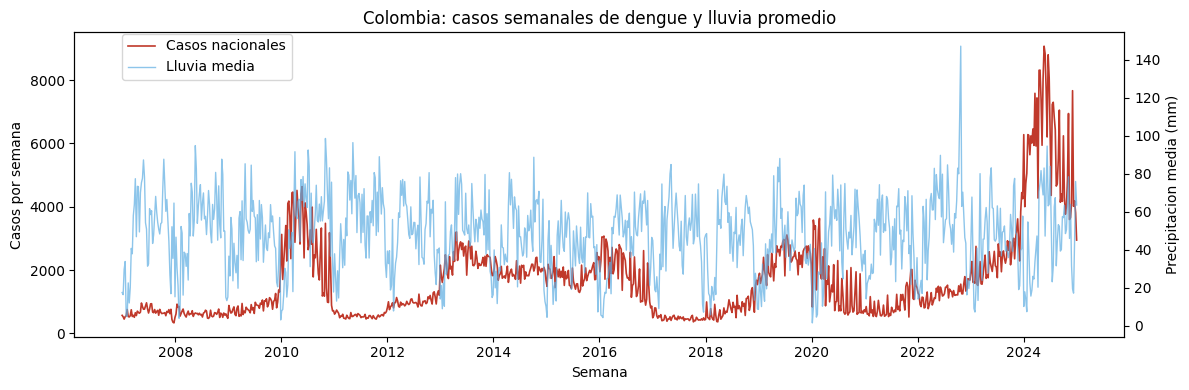

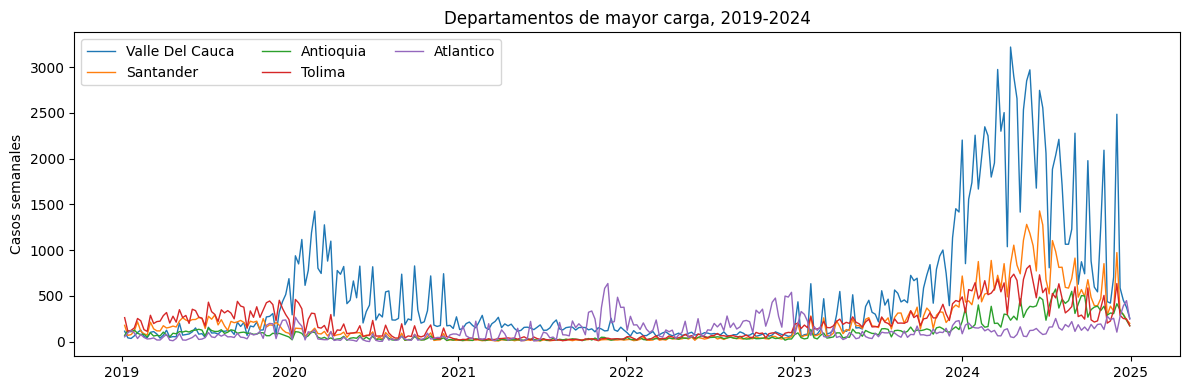

In [12]:
national = (
    train.groupby("semana_inicio", as_index=False)
    .agg(casos=("casos_dengue", "sum"), lluvia=("precip_chirps_mm", "mean"))
)
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(national.semana_inicio, national.casos, color="#C0392B", lw=1.2, label="Casos nacionales")
ax1.set_ylabel("Casos por semana")
ax2 = ax1.twinx()
ax2.plot(national.semana_inicio, national.lluvia, color="#5DADE2", alpha=0.7, lw=1, label="Lluvia media")
ax2.set_ylabel("Precipitacion media (mm)")
ax1.set_title("Colombia: casos semanales de dengue y lluvia promedio")
ax1.set_xlabel("Semana")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.92))
plt.tight_layout()
plt.show()

focus = ["Valle Del Cauca", "Santander", "Antioquia", "Tolima", "Atlantico"]
recent = train[train.anio.between(2019, 2024)]
fig, ax = plt.subplots(figsize=(12, 4))
for name in focus:
    part = recent[recent.departamento == name]
    ax.plot(part.semana_inicio, part.casos_dengue, lw=1, label=name)
ax.set_title("Departamentos de mayor carga, 2019-2024")
ax.set_ylabel("Casos semanales")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()


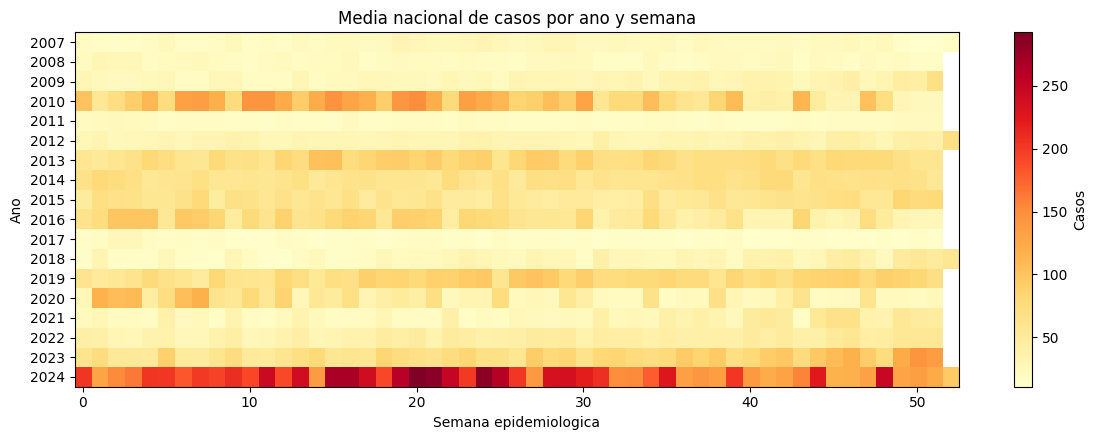

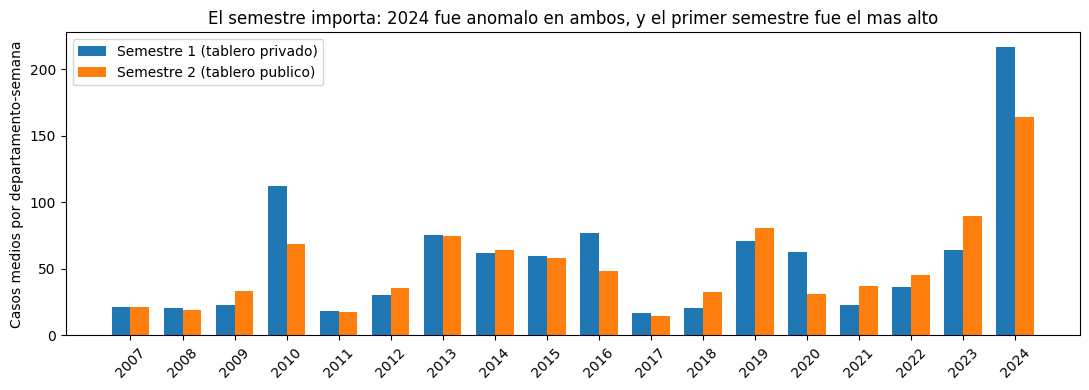

,semestre_1,semestre_2
anio,,
2019,70.8,81.0
2020,62.7,31.3
2021,22.7,37.2
2022,36.2,45.0
2023,64.3,90.0
2024,216.8,163.8


In [13]:
heat = train.pivot_table(index="anio", columns="semana", values="casos_dengue", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 4.5))
image = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Semana epidemiologica")
ax.set_ylabel("Ano")
ax.set_title("Media nacional de casos por ano y semana")
fig.colorbar(image, ax=ax, label="Casos")
plt.tight_layout()
plt.show()

by_year = pd.DataFrame({
    "semestre_1": train[train.semana <= 26].groupby("anio").casos_dengue.mean(),
    "semestre_2": train[train.semana >= 27].groupby("anio").casos_dengue.mean(),
})
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(by_year))
ax.bar(x - 0.18, by_year.semestre_1, width=0.36, label="Semestre 1 (tablero privado)")
ax.bar(x + 0.18, by_year.semestre_2, width=0.36, label="Semestre 2 (tablero publico)")
ax.set_xticks(x)
ax.set_xticklabels(by_year.index, rotation=45)
ax.set_ylabel("Casos medios por departamento-semana")
ax.set_title("El semestre importa: 2024 fue anomalo en ambos, y el primer semestre fue el mas alto")
ax.legend()
plt.tight_layout()
plt.show()
display(by_year.tail(6).round(1))


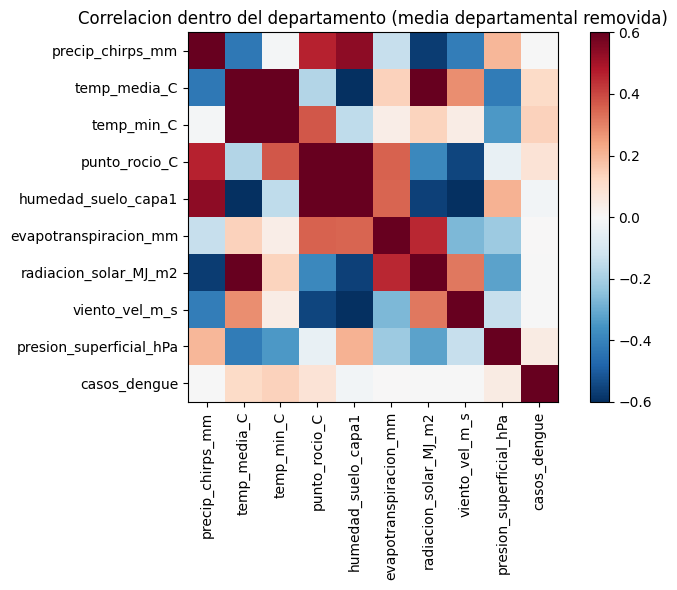

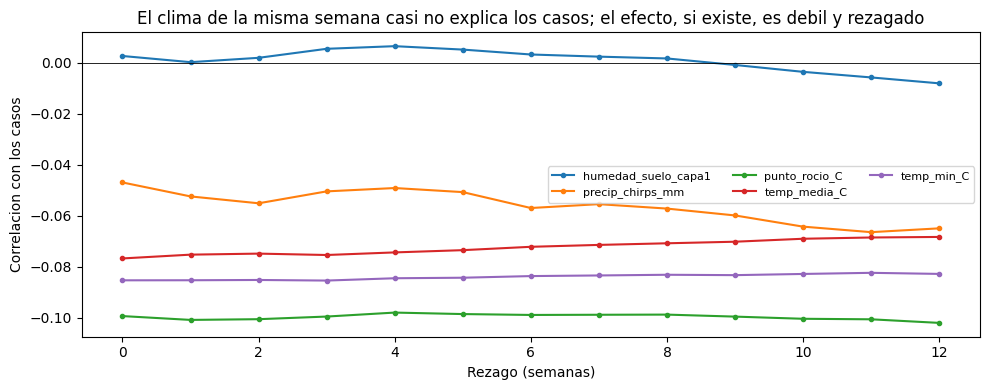

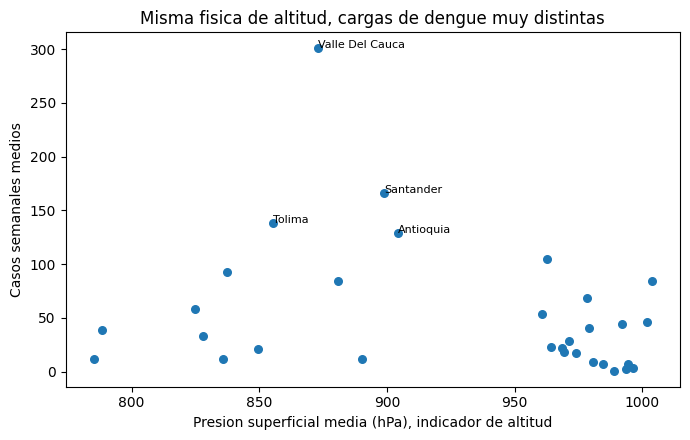

In [14]:
climate_cols = [
    "precip_chirps_mm", "temp_media_C", "temp_min_C", "punto_rocio_C",
    "humedad_suelo_capa1", "evapotranspiracion_mm", "radiacion_solar_MJ_m2",
    "viento_vel_m_s", "presion_superficial_hPa", "casos_dengue",
]
demeaned = train[climate_cols + ["id_departamento"]].copy()
for col in climate_cols:
    demeaned[col] = demeaned[col] - demeaned.groupby("id_departamento")[col].transform("mean")
corr = demeaned[climate_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
ax.set_title("Correlacion dentro del departamento (media departamental removida)")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

def lagged_correlation(column, lag):
    pieces = []
    for _, group in train.groupby("id_departamento"):
        pieces.append(pd.DataFrame({"x": group[column].shift(lag), "y": group["casos_dengue"]}))
    pair = pd.concat(pieces, ignore_index=True).dropna()
    return float(pair.x.corr(pair.y))

lag_rows = []
for column in ["precip_chirps_mm", "temp_media_C", "temp_min_C", "humedad_suelo_capa1", "punto_rocio_C"]:
    for lag in range(0, 13):
        lag_rows.append({"variable": column, "rezago_semanas": lag, "correlacion": lagged_correlation(column, lag)})
lag_table = pd.DataFrame(lag_rows)
fig, ax = plt.subplots(figsize=(10, 4))
for variable, part in lag_table.groupby("variable"):
    ax.plot(part.rezago_semanas, part.correlacion, marker="o", ms=3, label=variable)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Rezago (semanas)")
ax.set_ylabel("Correlacion con los casos")
ax.set_title("El clima de la misma semana casi no explica los casos; el efecto, si existe, es debil y rezagado")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(dept_level.presion, dept_level.media, s=30)
for _, row in dept_level.head(4).iterrows():
    ax.annotate(row.departamento, (row.presion, row.media), fontsize=8)
ax.set_xlabel("Presion superficial media (hPa), indicador de altitud")
ax.set_ylabel("Casos semanales medios")
ax.set_title("Misma fisica de altitud, cargas de dengue muy distintas")
plt.tight_layout()
plt.show()


## Lectura del analisis exploratorio y variables que si se pueden usar

Los picos nacionales de 2010, 2013, 2016, 2019 y sobre todo 2023-2024 no son un ciclo semanal suave. 2024 rompe la escala: la media del primer semestre fue cerca de 217 casos por departamento-semana y la del segundo cerca de 164, frente a una historia previa mucho mas baja. Ese quiebre importa dos veces. El tablero privado mira enero-junio de 2025, justo el semestre que en 2024 fue el peor, y el publico mira julio-diciembre. Un modelo calibrado solo con el promedio 2007-2023 va a subestimar si el regimen alto continua, y uno que copie 2024 semana a semana va a fallar si 2025 revierte.

Dentro de cada departamento la correlacion lineal del clima con los casos es debil. Tiene sentido biologico: el *Aedes aegypti* responde a lluvia y temperatura con varias semanas de rezago (huevo, larva, adulto, incubacion), y ademas la presion y la temperatura absoluta identifican la altitud del departamento mas que el brote de esa semana. La presion de Vaupes y la de Quindio dicen donde queda el territorio, no cuantos casos vendran el martes.

Por eso las redes no reciben el conteo de la semana que deben predecir. Reciben tres bloques, todos conocidos antes de cerrar la semana objetivo o directamente publicados en `test.parquet`:

1. **Clima exogeno de la ventana**, incluida la semana a pronosticar, porque el archivo de 2025 trae esas columnas. En la segunda etapa se agregan anomalias contra el clima normal de ese departamento y esa semana, y medias moviles de 4 semanas de lluvia, temperatura y humedad.
2. **Calendario.** Seno y coseno de la semana epidemiologica, para no tratar la semana 52 y la 1 como numeros lejanos. La direccion del viento pasa al mismo formato circular en la etapa 2: 0 y 360 grados son el mismo viento.
3. **Memoria epidemiologica anterior al ano del pronostico.** Media historica del departamento, anclas de las ultimas 8 y 26 semanas del ano previo, casos de la misma semana un ano atras, perfil estacional y la forma `ancla_26 * perfil_estacional / media_historica`. Nada de esto usa casos del ano que se esta prediciendo.

La media historica es la variable que el codigo base no tenia. Sin ella, dos departamentos con clima parecido y poblaciones distintas producen el mismo pronostico. El MSE de la competencia no perdona ese error en Valle del Cauca.


## Preparacion sin fuga y forma de los tensores

El corte de validacion de las fases 2 a 5 es 2024 completo: se entrena con anos anteriores y se evaluan las 53 semanas de 2024. El el escalador se ajusta solo con filas de entrenamiento.

La ventana de longitud L termina en la semana objetivo e incluye clima y calendario de esa semana. No incluye `casos_dengue`. Para puntuar la semana 1 de 2024, la ventana se apoya en las ultimas semanas de 2023; por eso el conjunto de validacion se construye sobre la serie completa y no sobre un recorte que empiece el 1 de enero.

Organizacion por arquitectura, que es distinta aunque la tabla de ejemplos sea la misma:

- **MLP.** La ventana se aplana a un vector `(lote, longitud por numero de variables)`. Una capa densa no tiene eje temporal; el orden queda grabado en la posicion del vector.
- **RNN, LSTM y GRU.** El tensor queda en `(lote, longitud, numero de variables)`. La celda recorre el tiempo y la capa final lee solo el ultimo estado oculto.
- **TCN.** Entra el mismo tensor 3D, se transpone a `(lote, numero de variables, longitud)` para la convolucion de una dimension y el relleno causal se pone solo a la izquierda. La salida usa el ultimo paso de tiempo. Asi la prediccion de la semana t no ve el clima de t+1.


In [15]:
features = build_features(train)
assert_no_year_leak(features, train)
COLS_STAGE1 = stage1_columns()
COLS_STAGE2 = stage2_columns()
print("Filas con historia suficiente:", features.shape)
print("Variables de la etapa 1:", len(COLS_STAGE1), COLS_STAGE1)
print("Variables de la etapa 2:", len(COLS_STAGE2))
print("Nulos etapa 2:", int(features[COLS_STAGE2].isna().sum().sum()))

scaled_demo, _ = scale_features(features, COLS_STAGE1, features.anio < VAL_YEAR)
demo = WindowDataset(scaled_demo, COLS_STAGE1, seq_len=8, target_years={2024}, residual=False)
x0, y0, y_raw0, shape0, id0, week0, dept0 = demo[0]
print("Ejemplo de validacion", id0, dept0, "semana", week0)
print("MLP / RNN ven X con forma", tuple(x0.shape), "-> MLP lo aplana a", int(np.prod(x0.shape)))
print("y (casos) =", float(y_raw0), "| el objetivo no esta dentro de la entrada")
print("Ventanas de entrenamiento < 2024:", len(WindowDataset(scaled_demo, COLS_STAGE1, 8, set(range(2008, 2024)), False)))
print("Ventanas de validacion 2024:", len(demo))


Filas con historia suficiente: (27497, 50)
Variables de la etapa 1: 14 ['precip_chirps_mm', 'temp_media_C', 'temp_max_C', 'temp_min_C', 'punto_rocio_C', 'humedad_suelo_capa1', 'evapotranspiracion_mm', 'radiacion_solar_MJ_m2', 'viento_vel_m_s', 'viento_dir_grados', 'presion_superficial_hPa', 'week_sin', 'week_cos', 'log_dmean']
Variables de la etapa 2: 35
Nulos etapa 2: 0
Ejemplo de validacion 1_2024_1 Amazonas semana 1
MLP / RNN ven X con forma (8, 14) -> MLP lo aplana a 112
y (casos) = 17.0 | el objetivo no esta dentro de la entrada


Ventanas de entrenamiento < 2024: 25637
Ventanas de validacion 2024: 1643


In [16]:
def plot_histories(names, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    for name in names:
        history = HISTORIES.get(name)
        if not history:
            continue
        ax.plot([row["epoch"] for row in history], [row["val_mse"] for row in history], marker="o", ms=3, label=name)
    ax.set_xlabel("Epoca")
    ax.set_ylabel("MSE de validacion 2024")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def show_models(names):
    table = pd.DataFrame(RESULTS)
    table = table[table.modelo.isin(names)].set_index("modelo")
    columns = ["familia", "etapa", "seq_len", "n_params", "epochs_ran", "val_mse", "val_rmse", "val_mae", "val_r2", "mse_h1", "mse_h2"]
    display(table[columns].rename(columns={"seq_len": "longitud", "n_params": "parametros", "epochs_ran": "epocas", "val_mse": "mse_validacion", "val_rmse": "raiz_mse", "val_mae": "mae_validacion", "val_r2": "r2_validacion", "mse_h1": "mse_semestre_1", "mse_h2": "mse_semestre_2"}).round(3))


def compare_pair(base_name, opt_name):
    table = pd.DataFrame(RESULTS).set_index("modelo")
    base, opt = table.loc[base_name], table.loc[opt_name]
    if pd.isna(base.val_mse) or pd.isna(opt.val_mse):
        print(f"No se compara {base_name} contra {opt_name} porque un entrenamiento no termino.")
        return
    delta = float(opt.val_mse - base.val_mse)
    direction = "reduce" if delta < 0 else "aumenta"
    print(
        f"{opt_name} {direction} el MSE de 2024 frente a {base_name}: "
        f"{base.val_mse:.0f} -> {opt.val_mse:.0f} ({delta:+.0f}). "
        f"Semestre 1: {base.mse_h1:.0f} -> {opt.mse_h1:.0f}. "
        f"Semestre 2: {base.mse_h2:.0f} -> {opt.mse_h2:.0f}."
    )
    if delta > 0:
        print("Mas capacidad no corrigio el error. El limite esta en las variables y en el cambio de regimen, no en el numero de capas.")
    else:
        print("La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.")


### Corrida de un experimento

Cada corrida entrena con los anos anteriores a 2024, mide 2024 y guarda el historial. Si una red no termina, la tabla sigue y esa fila queda vacia.


In [17]:
def run_experiment(name, family, stage, factory, columns, seq_len, residual, train_kwargs, frame, epochs, patience):
    print(f"\n=== {name} | longitud={seq_len} | residual={residual} | variables={len(columns)} ===")
    try:
        n_params = count_parameters(factory())
        reset_seed(42)
        fit_mask = frame["anio"] < VAL_YEAR
        scaled, _scaler = scale_features(frame, columns, fit_mask)
        train_years = {int(year) for year in frame.loc[fit_mask, "anio"].unique()}
        train_ds = WindowDataset(scaled, columns, seq_len, train_years, residual)
        val_ds = WindowDataset(scaled, columns, seq_len, {VAL_YEAR}, residual)
        print(f"ventanas de entrenamiento={len(train_ds)} validacion={len(val_ds)} parametros={n_params}")
        model, history, _scores = train_forecaster(
            factory(),
            make_loader(train_ds, BATCH_SIZE, True),
            make_loader(val_ds, BATCH_SIZE, False),
            DEVICE,
            residual,
            epochs=epochs,
            patience=patience,
            **train_kwargs,
        )
        preds = collect_predictions(model, make_loader(val_ds, BATCH_SIZE, False), DEVICE, residual)
        scores = regression_scores(preds)
        epochs_ran = len(history)
        HISTORIES[name] = history
        PREDICTIONS[name] = preds
    except Exception as exc:
        print(f"FALLO {name}: {type(exc).__name__}: {exc}")
        n_params = 0
        epochs_ran = 0
        scores = {"val_mse": np.nan, "val_rmse": np.nan, "val_mae": np.nan, "val_r2": np.nan, "mse_h1": np.nan, "mse_h2": np.nan}
    SPECS[name] = {
        "name": name,
        "family": family,
        "stage": stage,
        "factory": factory,
        "columns": columns,
        "seq_len": seq_len,
        "residual": residual,
        "train_kwargs": train_kwargs,
    }
    RESULTS.append({
        "modelo": name,
        "familia": family,
        "etapa": stage,
        "seq_len": seq_len,
        "residual": residual,
        "n_features": len(columns),
        "n_params": n_params,
        "epochs_ran": epochs_ran,
        **scores,
    })
    return scores


## 2. Perceptron multicapa

El MLP del codigo base es una capa de 64 unidades, ReLU, otra capa lineal y un ReLU final que anula el gradiente cuando la prediccion cae a cero. Entrena con Adam a 0.001, MSE, ventana de 5 semanas y lotes de 32, y no sabe que departamento esta viendo.

Aqui las dos variantes comparten las variables de la etapa 1 (clima, calendario y log de la media historica del departamento) y el mismo corte 2024. El tamano de lote pasa a 256 en todas las redes: con 24 mil ventanas, 32 ejemplos por paso alarga el entrenamiento y no es la pregunta de arquitectura. Los cambios que si se comparan, de la variante base a la optimizada, son estos cuatro (en realidad seis):

| Hiperparametro | Variante base | Variante optimizada |
| --- | --- | --- |
| Capas ocultas | 64 | 128, 64, 32 |
| Activacion | ReLU, tambien en la salida | GELU y salida lineal |
| Regularizacion | ninguna | abandono 0.2 y normalizacion por lote y AdamW con decaimiento de pesos 1e-4 |
| Ventana, tasa y planificador | ventana de 8, tasa=0.001, sin planificador | ventana de 16, tasa=0.0005, reduccion de la tasa si la validacion se estanca |

La salida lineal es deliberada. El ReLU final del codigo base impide predecir cero con gradiente y aplasta brotes pequenos.



=== MLP base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=7297


  epoca 01 | entrenamiento 9350.9 | validacion 155654.1 | semestre 1 220033.2 | semestre 2 93659.5


  epoca 02 | entrenamiento 7961.9 | validacion 145957.2 | semestre 1 208259.5 | semestre 2 85962.4


  epoca 03 | entrenamiento 6770.8 | validacion 136771.0 | semestre 1 196434.7 | semestre 2 79317.1


  epoca 04 | entrenamiento 5828.2 | validacion 127324.1 | semestre 1 184108.5 | semestre 2 72642.7


... (27 outputs left out)

  epoca 15 | entrenamiento 7722.7 | validacion 143490.7 | semestre 1 202886.2 | semestre 2 86295.0


  epoca 16 | entrenamiento 7563.2 | validacion 144845.5 | semestre 1 204501.7 | semestre 2 87398.7


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
MLP base,MLP,1,8,7297,16,117530.836,342.828,134.273,0.071,170463.922,66558.242
MLP optimizado,MLP,1,16,39617,16,143490.656,378.802,172.428,-0.135,202886.172,86294.961


MLP optimizado aumenta el MSE de 2024 frente a MLP base: 117531 -> 143491 (+25960). Semestre 1: 170464 -> 202886. Semestre 2: 66558 -> 86295.
Mas capacidad no corrigio el error. El limite esta en las variables y en el cambio de regimen, no en el numero de capas.


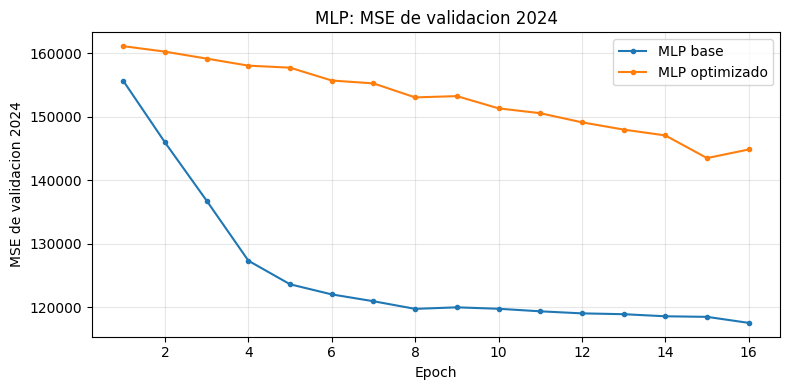

In [9]:
mlp_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
mlp_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "MLP base", "MLP", 1,
    lambda: MLPForecaster(len(COLS_STAGE1), 8, (64,), 0.0, "relu", False, True),
    COLS_STAGE1, 8, False, mlp_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "MLP optimizado", "MLP", 1,
    lambda: MLPForecaster(len(COLS_STAGE1), 16, (128, 64, 32), 0.2, "gelu", True, False),
    COLS_STAGE1, 16, False, mlp_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["MLP base", "MLP optimizado"])
compare_pair("MLP base", "MLP optimizado")
plot_histories(["MLP base", "MLP optimizado"], "MLP: MSE de validacion 2024")


## 3. RNN simple

La RNN del curso (`RNNModel`) recorre la ventana y proyecta el ultimo estado con una capa lineal. No tiene compuertas, asi que alargar la memoria compite con el desvanecimiento del gradiente. Por eso la variante optimizada no solo agranda la red: cambia la no linealidad, apila una segunda capa con abandono y acorta el paso de Adam. El recorte de gradiente a norma 1 va en las dos variantes; sin eso la RNN con ReLU diverge con conteos de cientos de casos.

| Hiperparametro | Variante base | Variante optimizada |
| --- | --- | --- |
| tamano oculto | 32 | 96 |
| numero de capas | 1 | 2 |
| no linealidad y abandono | tangente hiperbolica, sin abandono | ReLU, abandono 0.2 y cabeza densa de 32 |
| Ventana y optimizador | ventana de 8, Adam 1e-3 | ventana de 16, AdamW 5e-4 con planificador |



=== RNN base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=1569


  epoca 01 | entrenamiento 9674.4 | validacion 160609.2 | semestre 1 225833.2 | semestre 2 97800.8


  epoca 02 | entrenamiento 9303.2 | validacion 159269.7 | semestre 1 224296.2 | semestre 2 96651.5


  epoca 03 | entrenamiento 9022.6 | validacion 158019.6 | semestre 1 222857.8 | semestre 2 95582.8


  epoca 04 | entrenamiento 8776.5 | validacion 156813.9 | semestre 1 221467.0 | semestre 2 94555.3


... (24 outputs left out)

  epoca 12 | entrenamiento 3979.8 | validacion 91494.4 | semestre 1 134516.8 | semestre 2 50065.3


  epoca 13 | entrenamiento 3745.9 | validacion 89178.5 | semestre 1 131136.2 | semestre 2 48774.9
  parada temprana en la epoca 13


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
RNN base,RNN,1,8,1569,16,147342.922,383.853,160.781,-0.165,210334.391,86684.492
RNN optimizada,RNN,1,16,32513,13,87527.375,295.850,112.200,0.308,129215.734,47383.016


RNN optimizada reduce el MSE de 2024 frente a RNN base: 147343 -> 87527 (-59816). Semestre 1: 210334 -> 129216. Semestre 2: 86684 -> 47383.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.


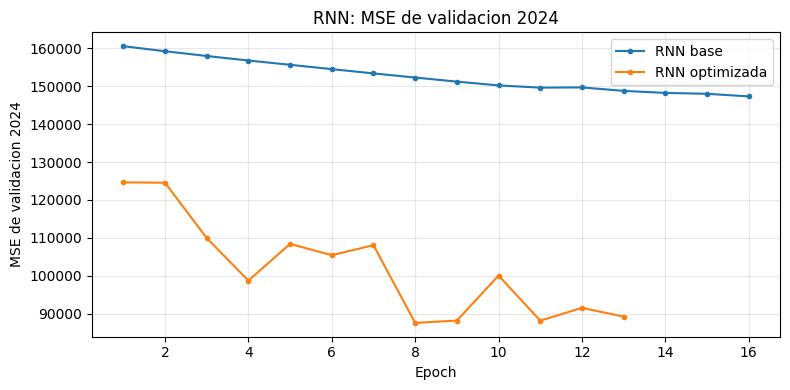

In [10]:
rnn_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
rnn_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "RNN base", "RNN", 1,
    lambda: RecurrentForecaster("rnn", len(COLS_STAGE1), 32, 1, 0.0, nonlinearity="tanh", head_hidden=0),
    COLS_STAGE1, 8, False, rnn_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "RNN optimizada", "RNN", 1,
    lambda: RecurrentForecaster("rnn", len(COLS_STAGE1), 96, 2, 0.2, nonlinearity="relu", head_hidden=32),
    COLS_STAGE1, 16, False, rnn_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["RNN base", "RNN optimizada"])
compare_pair("RNN base", "RNN optimizada")
plot_histories(["RNN base", "RNN optimizada"], "RNN: MSE de validacion 2024")


## 4. LSTM y GRU

LSTM y GRU resuelven el mismo problema de memoria con distintas compuertas. LSTM mantiene un estado de celda aparte del estado oculto; GRU mezcla memoria y estado en menos parametros. El codigo base de la competencia no trae ninguna de las dos. La referencia de clase es una sola capa pequena. Aqui se entrenan las dos familias, cada una en version corta y version modificada, sobre las mismas variables de la etapa 1.

Cambios de la version base a la optimizada, en cada familia (son mas de cuatro):

| Hiperparametro | Base LSTM / GRU | LSTM optimizada | GRU optimizada |
| --- | --- | --- | --- |
| Tipo de celda | LSTM o GRU de 1 capa | LSTM | GRU |
| tamano oculto | 32 | 128 | 96 |
| numero de capas | 1 | 2 | 2 |
| Abandono y cabeza | sin abandono, cabeza lineal | abandono 0.3, cabeza 64 | abandono 0.2, cabeza 64 |
| Ventana y optimizador | ventana de 8, Adam 1e-3 | ventana de 16, AdamW 5e-4 y planificador | ventana de 12, AdamW 5e-4 y planificador |

En la libreria el abandono de la celda recurrente solo actua si hay al menos dos capas. Subir el abandono sin apilar capas no cambiaria nada; por eso `numero de capas` y el abandono se mueven juntos.



=== LSTM base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=6177


  epoca 01 | entrenamiento 9730.5 | validacion 160425.3 | semestre 1 225619.0 | semestre 2 97646.2


  epoca 02 | entrenamiento 9237.1 | validacion 158933.7 | semestre 1 223910.0 | semestre 2 96364.0


  epoca 03 | entrenamiento 8942.1 | validacion 157655.7 | semestre 1 222440.3 | semestre 2 95270.6


  epoca 04 | entrenamiento 8685.0 | validacion 156435.9 | semestre 1 221033.1 | semestre 2 94231.3


... (61 outputs left out)

  epoca 15 | entrenamiento 4317.4 | validacion 114181.9 | semestre 1 166226.4 | semestre 2 64064.9


  epoca 16 | entrenamiento 4318.9 | validacion 111061.2 | semestre 1 161778.8 | semestre 2 62222.1


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
LSTM base,LSTM,1,8,6177,16,147181.719,383.643,159.833,-0.164,210040.750,86650.789
LSTM optimizada,LSTM,1,16,214145,16,108235.539,328.992,123.633,0.144,160522.656,57884.980
GRU base,GRU,1,8,4641,16,147121.078,383.564,159.441,-0.163,210043.328,86529.258
GRU optimizada,GRU,1,12,94401,16,111061.227,333.258,121.477,0.122,161778.797,62222.109


LSTM optimizada reduce el MSE de 2024 frente a LSTM base: 147182 -> 108236 (-38946). Semestre 1: 210041 -> 160523. Semestre 2: 86651 -> 57885.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.
GRU optimizada reduce el MSE de 2024 frente a GRU base: 147121 -> 111061 (-36060). Semestre 1: 210043 -> 161779. Semestre 2: 86529 -> 62222.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.


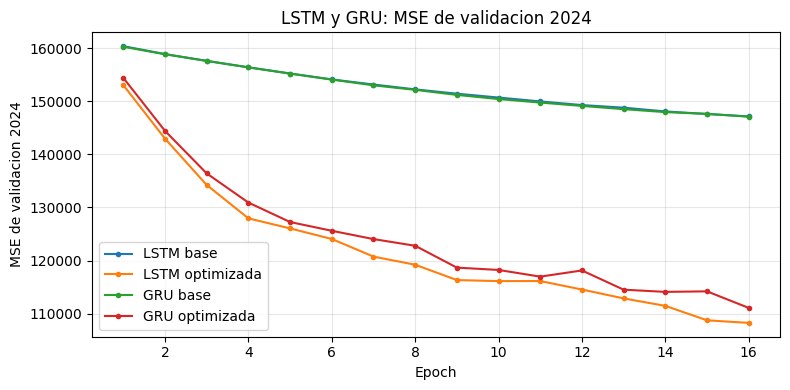

In [11]:
rec_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
rec_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "LSTM base", "LSTM", 1,
    lambda: RecurrentForecaster("lstm", len(COLS_STAGE1), 32, 1, 0.0, head_hidden=0),
    COLS_STAGE1, 8, False, rec_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "LSTM optimizada", "LSTM", 1,
    lambda: RecurrentForecaster("lstm", len(COLS_STAGE1), 128, 2, 0.3, head_hidden=64),
    COLS_STAGE1, 16, False, rec_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "GRU base", "GRU", 1,
    lambda: RecurrentForecaster("gru", len(COLS_STAGE1), 32, 1, 0.0, head_hidden=0),
    COLS_STAGE1, 8, False, rec_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "GRU optimizada", "GRU", 1,
    lambda: RecurrentForecaster("gru", len(COLS_STAGE1), 96, 2, 0.2, head_hidden=64),
    COLS_STAGE1, 12, False, rec_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["LSTM base", "LSTM optimizada", "GRU base", "GRU optimizada"])
compare_pair("LSTM base", "LSTM optimizada")
compare_pair("GRU base", "GRU optimizada")
plot_histories(
    ["LSTM base", "LSTM optimizada", "GRU base", "GRU optimizada"],
    "LSTM y GRU: MSE de validacion 2024",
)


## 5. TCN

El TCN del codigo base usa cuatro bloques residuales, filtro de tamano 3, abandono 0.1, normalizacion por grupos con un solo grupo y canales `[32, 32, 64, 64]`. Cada bloque tiene dos convoluciones causales con dilatacion `2^i`. El campo receptivo queda

`R = 1 + 2 * (filtro - 1) * (2^bloques - 1)`.

Con filtro de tamano 3 y 4 bloques, R = 61 pasos: mas largo que la ventana de 8, asi que parte del filtro mira ceros de relleno. La variante optimizada acorta la profundidad, agranda el filtro y alarga la ventana para que el campo y los datos se parezcan.

| Hiperparametro | TCN base (codigo de la competencia) | TCN optimizada |
| --- | --- | --- |
| Canales / bloques | 32, 32, 64, 64 (4 bloques, R=61) | 32, 32, 64 (3 bloques) |
| Tamano del filtro | 3 | 5 (R=57) |
| Abandono, activacion y norma | 0.1, ReLU, normalizacion por grupos, 1 grupo | 0.25, GELU, normalizacion por grupos, 4 grupos |
| Ventana y optimizador | ventana de 8, Adam 1e-3 | ventana de 20, AdamW 5e-4, decaimiento de pesos 1e-4 y planificador |


Campo receptivo base: 61
Campo receptivo optimizado: 57

=== TCN base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=57377


  epoca 01 | entrenamiento 7178.9 | validacion 133209.9 | semestre 1 192919.2 | semestre 2 75712.0


  epoca 02 | entrenamiento 5343.5 | validacion 126503.2 | semestre 1 183034.8 | semestre 2 72065.4


  epoca 03 | entrenamiento 5012.6 | validacion 118340.9 | semestre 1 171700.4 | semestre 2 66957.7


  epoca 04 | entrenamiento 4778.6 | validacion 117479.2 | semestre 1 170093.4 | semestre 2 66813.7


... (27 outputs left out)

  epoca 15 | entrenamiento 3492.5 | validacion 97638.6 | semestre 1 139360.4 | semestre 2 57462.0


  epoca 16 | entrenamiento 3454.6 | validacion 94121.3 | semestre 1 137691.0 | semestre 2 52165.4


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
TCN base,TCN,1,8,57377,16,95672.242,309.309,125.026,0.244,133367.844,59372.762
TCN optimizada,TCN,1,20,51745,16,94121.328,306.792,119.390,0.256,137690.953,52165.391


TCN optimizada reduce el MSE de 2024 frente a TCN base: 95672 -> 94121 (-1551). Semestre 1: 133368 -> 137691. Semestre 2: 59373 -> 52165.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.


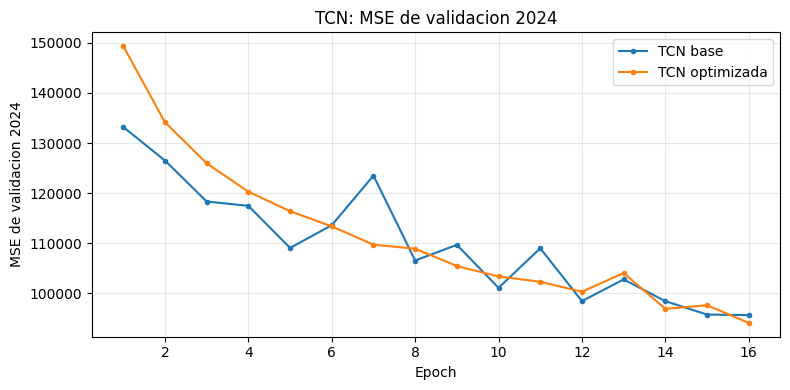

In [12]:
print("Campo receptivo base:", 1 + 2 * (3 - 1) * (2 ** 4 - 1))
print("Campo receptivo optimizado:", 1 + 2 * (5 - 1) * (2 ** 3 - 1))

tcn_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
tcn_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "TCN base", "TCN", 1,
    lambda: TCNForecaster(len(COLS_STAGE1), (32, 32, 64, 64), 3, 0.1, 1, "relu"),
    COLS_STAGE1, 8, False, tcn_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "TCN optimizada", "TCN", 1,
    lambda: TCNForecaster(len(COLS_STAGE1), (32, 32, 64), 5, 0.25, 4, "gelu"),
    COLS_STAGE1, 20, False, tcn_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["TCN base", "TCN optimizada"])
compare_pair("TCN base", "TCN optimizada")
plot_histories(["TCN base", "TCN optimizada"], "TCN: MSE de validacion 2024")


## Comparacion de la etapa 1

Todas las redes de arriba responden la misma pregunta: dado el clima reciente, el calendario y el nivel historico del departamento, cual es el conteo de la semana. Ninguna ve los casos de 2024 durante el entrenamiento. La referencia epidemiologica de esta tabla no es una red: es la forma `ancla de 26 semanas de 2023 * perfil estacional / media historica`. Sirve para saber si la red esta aprendiendo algo que esa regla no diga ya.


,modelo,familia,etapa,mse_validacion,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2,parametros
10,Forma estacional escalada,Referencia,0,76519.082,115.136,0.395,112001.800,42350.540,0
3,RNN optimizada,RNN,1,87527.375,112.200,0.308,129215.734,47383.016,32513
9,TCN optimizada,TCN,1,94121.328,119.390,0.256,137690.953,52165.391,51745
8,TCN base,TCN,1,95672.242,125.026,0.244,133367.844,59372.762,57377
5,LSTM optimizada,LSTM,1,108235.539,123.633,0.144,160522.656,57884.980,214145
7,GRU optimizada,GRU,1,111061.227,121.477,0.122,161778.797,62222.109,94401
11,Misma semana del ano anterior,Referencia,0,117021.758,138.334,0.075,180038.258,56339.203,0
0,MLP base,MLP,1,117530.836,134.273,0.071,170463.922,66558.242,7297
12,Perfil estacional historico,Referencia,0,122123.779,144.917,0.034,176427.151,69831.642,0
1,MLP optimizado,MLP,1,143490.656,172.428,-0.135,202886.172,86294.961,39617


Mejor red de la etapa 1 en 2024: RNN optimizada


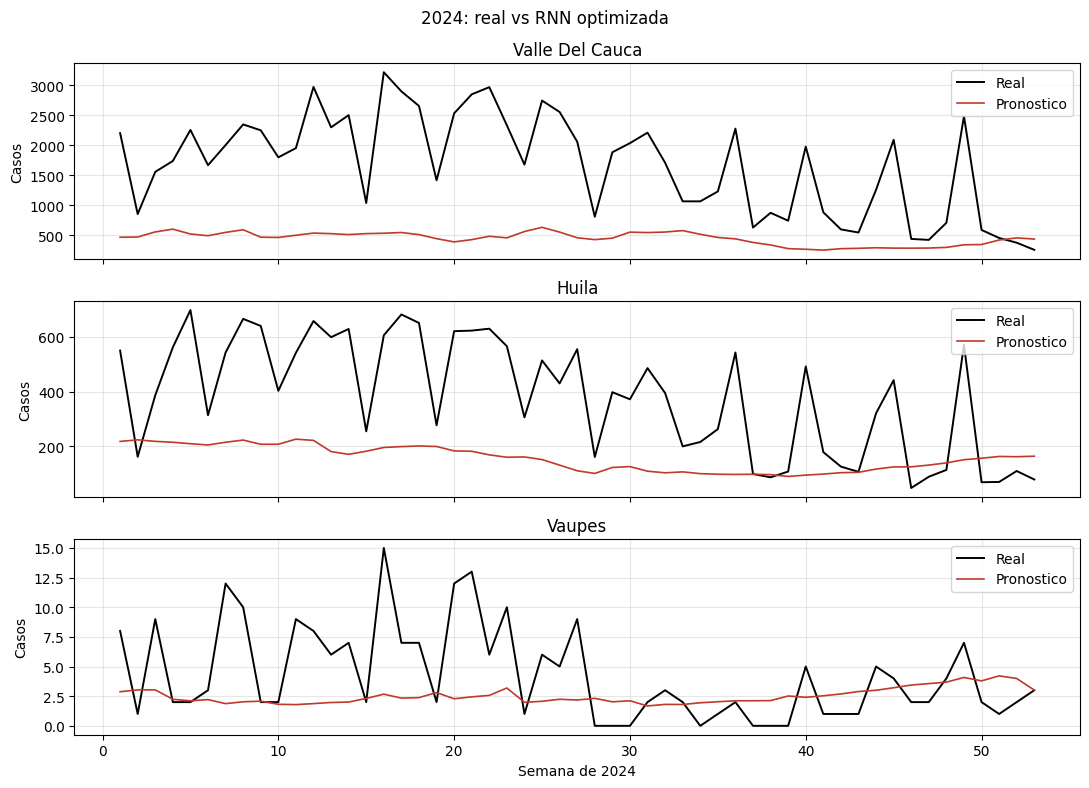

In [13]:
def add_reference(name, prediction):
    frame = pd.DataFrame({
        "y": features.loc[features.anio == VAL_YEAR, "casos_dengue"].to_numpy(),
        "pred": np.clip(prediction, 0, None),
        "semana": features.loc[features.anio == VAL_YEAR, "semana"].to_numpy(),
    })
    scores = regression_scores(frame)
    RESULTS.append({
        "modelo": name,
        "familia": "Referencia",
        "etapa": 0,
        "seq_len": 0,
        "residual": False,
        "n_features": 0,
        "n_params": 0,
        "epochs_ran": 0,
        **scores,
    })


val_2024 = features[features.anio == VAL_YEAR]
add_reference("Forma estacional escalada", val_2024["shape"].to_numpy())
add_reference("Misma semana del ano anterior", val_2024["yoy"].to_numpy())
add_reference("Perfil estacional historico", val_2024["seas"].to_numpy())

summary = pd.DataFrame(RESULTS).sort_values("val_mse")
display(summary[["modelo", "familia", "etapa", "val_mse", "val_mae", "val_r2", "mse_h1", "mse_h2", "n_params"]].rename(columns={"val_mse": "mse_validacion", "val_mae": "mae_validacion", "val_r2": "r2_validacion", "mse_h1": "mse_semestre_1", "mse_h2": "mse_semestre_2", "n_params": "parametros"}).round(3))

best_stage1_name = summary[summary.etapa == 1].sort_values("val_mse").iloc[0]["modelo"]
print("Mejor red de la etapa 1 en 2024:", best_stage1_name)

preview = PREDICTIONS[best_stage1_name]
plot_departments = ["Valle Del Cauca", "Huila", "Vaupes"]


def plot_forecast(pred_df, title):
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for ax, dept in zip(axes, plot_departments):
        part = pred_df[pred_df.departamento == dept].sort_values("semana")
        ax.plot(part.semana, part.y, color="black", lw=1.4, label="Real")
        ax.plot(part.semana, part.pred, color="#C0392B", lw=1.2, label="Pronostico")
        ax.set_ylabel("Casos")
        ax.set_title(dept)
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
    axes[-1].set_xlabel("Semana de 2024")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_forecast(preview, f"2024: real vs {best_stage1_name}")


## Etapa 2. Corregir un perfil, no reinventar el nivel

2024 no se parece a la media de la decada anterior. Una red que tiene que inventar desde cero el nivel de Valle del Cauca gasta capacidad en algo que ya dice la historia reciente del departamento. La etapa 2 cambia la pregunta: el objetivo de entrenamiento pasa a ser el residual `casos - forma_estacional_escalada`, y al predecir se suma de nuevo esa forma. El MSE que se reporta y la parada temprana siguen calculados sobre los casos, no sobre el residual, porque esa es la metrica de Kaggle.

Las variables adicionales salen del analisis exploratorio: anclas de 8 y 26 semanas, perfil y rezago anual, anomalias climaticas, medias moviles de 4 semanas y viento en seno/coseno. Las redes de esta etapa son las versiones optimizadas de GRU, LSTM y TCN, que son las que mejor retienen una ventana larga.

El peso del ensamble no se elige mirando solo 2024. 2024 aplasta cualquier promedio de MSE porque sus errores son enormes. Se maximiza el R2 medio de 2022, 2023 y 2024, para que un ano epidemico y un ano tranquilo voten parejo. Eso protege a la vez el semestre que vera el tablero publico y el que vera el privado, sin conocer 2025.


In [14]:
STAGE2_SPECS = {
    "GRU residual": {
        "factory": lambda: RecurrentForecaster("gru", len(COLS_STAGE2), 96, 2, 0.2, head_hidden=64),
        "seq_len": 12,
        "train_kwargs": dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw"),
    },
    "LSTM residual": {
        "factory": lambda: RecurrentForecaster("lstm", len(COLS_STAGE2), 128, 2, 0.3, head_hidden=64),
        "seq_len": 16,
        "train_kwargs": dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw"),
    },
    "TCN residual": {
        "factory": lambda: TCNForecaster(len(COLS_STAGE2), (32, 32, 64), 5, 0.25, 4, "gelu"),
        "seq_len": 20,
        "train_kwargs": dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw"),
    },
}

VALIDACION_HISTORICA = {}


def validar_anio(name, spec, year):
    print(f"\n=== validacion historica {name} -> {year} ===")
    reset_seed(42)
    fit_mask = features["anio"] < year
    scaled, _scaler = scale_features(features, COLS_STAGE2, fit_mask)
    train_years = {int(value) for value in features.loc[fit_mask, "anio"].unique()}
    train_ds = WindowDataset(scaled, COLS_STAGE2, spec["seq_len"], train_years, True)
    val_ds = WindowDataset(scaled, COLS_STAGE2, spec["seq_len"], {year}, True)
    model, _history, _scores = train_forecaster(
        spec["factory"](),
        make_loader(train_ds, BATCH_SIZE, True),
        make_loader(val_ds, BATCH_SIZE, False),
        DEVICE,
        True,
        epochs=EPOCAS_VALIDACION,
        patience=PACIENCIA_VALIDACION,
        **spec["train_kwargs"],
    )
    preds = collect_predictions(model, make_loader(val_ds, BATCH_SIZE, False), DEVICE, True)
    VALIDACION_HISTORICA[(name, year)] = preds
    nombres_metrica = {
        "val_mse": "mse_validacion",
        "val_rmse": "raiz_mse",
        "val_r2": "r2_validacion",
        "mse_h1": "mse_semestre_1",
        "mse_h2": "mse_semestre_2",
    }
    visibles = {
        nombres_metrica[clave]: round(valor, 1)
        for clave, valor in regression_scores(preds).items()
        if clave in nombres_metrica and ("mse" in clave or clave == "val_r2")
    }
    print(name, year, visibles)
    return preds


for model_name, model_spec in STAGE2_SPECS.items():
    for holdout_year in (2022, 2023, 2024):
        validar_anio(model_name, model_spec, holdout_year)



=== validacion historica GRU residual -> 2022 ===


  epoca 01 | entrenamiento 6721.7 | validacion 1284.4 | semestre 1 1206.1 | semestre 2 1362.7


  epoca 02 | entrenamiento 6168.7 | validacion 1152.7 | semestre 1 1087.2 | semestre 2 1218.2


  epoca 03 | entrenamiento 5608.0 | validacion 1067.5 | semestre 1 971.6 | semestre 2 1163.4


  epoca 04 | entrenamiento 5064.2 | validacion 918.5 | semestre 1 810.8 | semestre 2 1026.1


  epoca 05 | entrenamiento 4613.9 | validacion 1006.3 | semestre 1 962.6 | semestre 2 1050.0


... (74 outputs left out)

  epoca 09 | entrenamiento 2826.6 | validacion 53090.6 | semestre 1 73828.0 | semestre 2 33121.2


  epoca 10 | entrenamiento 2621.7 | validacion 61335.8 | semestre 1 82319.8 | semestre 2 41128.9


  epoca 11 | entrenamiento 2495.7 | validacion 54419.1 | semestre 1 74266.2 | semestre 2 35307.0


  epoca 12 | entrenamiento 2358.3 | validacion 56666.7 | semestre 1 78445.2 | semestre 2 35694.8
TCN residual 2024 {'mse_validacion': 53090.6, 'raiz_mse': 230.4, 'r2_validacion': 0.6, 'mse_semestre_1': 73828.0, 'mse_semestre_2': 33121.2}


In [15]:
def year_bundle(year):
    base = features.loc[features.anio == year, ["ID", "casos_dengue", "semana", "departamento", "shape", "seas", "yoy"]].rename(
        columns={"casos_dengue": "y"}
    )
    merged = base.copy()
    for model_name in STAGE2_SPECS:
        part = VALIDACION_HISTORICA[(model_name, year)][["ID", "pred"]].rename(columns={"pred": model_name})
        merged = merged.merge(part, on="ID", how="inner")
    for column in ["shape", "seas", "yoy"]:
        merged[column] = merged[column].clip(lower=0)
    return merged


def compositions(n_parts, total):
    if n_parts == 1:
        yield (total,)
        return
    for count in range(total + 1):
        for rest in compositions(n_parts - 1, total - count):
            yield (count,) + rest


BLEND_NAMES = ["GRU residual", "LSTM residual", "TCN residual", "shape"]
bundles = {year: year_bundle(year) for year in (2022, 2023, 2024)}
for year, bundle in bundles.items():
    print(year, "filas alineadas", len(bundle), "de", int((features.anio == year).sum()))

best_weights = None
best_r2 = -1e9
weight_rows = []
for counts in compositions(len(BLEND_NAMES), 10):
    weights = np.array(counts, dtype=float) / 10.0
    r2_values = []
    mse_values = []
    for bundle in bundles.values():
        prediction = np.clip(sum(weights[i] * bundle[name].to_numpy() for i, name in enumerate(BLEND_NAMES)), 0, None)
        r2_values.append(r2_score(bundle.y, prediction))
        mse_values.append(mean_squared_error(bundle.y, prediction))
    mean_r2 = float(np.mean(r2_values))
    weight_rows.append({"peso_" + ("forma" if name == "shape" else name): weights[i] for i, name in enumerate(BLEND_NAMES)} | {
        "r2_medio": mean_r2,
        "mse_2022": mse_values[0],
        "mse_2023": mse_values[1],
        "mse_2024": mse_values[2],
    })
    if mean_r2 > best_r2:
        best_r2 = mean_r2
        best_weights = weights

weight_table = pd.DataFrame(weight_rows).sort_values("r2_medio", ascending=False)
print("Mejor peso por R2 medio de 2022-2024:", dict(zip(["GRU residual", "LSTM residual", "TCN residual", "forma"], best_weights.round(2))), "R2 medio", round(best_r2, 3))
display(weight_table.head(8).round(3))

single_rows = []
for model_name in list(STAGE2_SPECS) + ["shape", "yoy", "seas"]:
    record = {"modelo": model_name}
    for year, bundle in bundles.items():
        column = model_name if model_name in bundle.columns else None
        prediction = bundle[model_name].to_numpy() if column else None
        if prediction is None:
            continue
        record[f"mse_{year}"] = mean_squared_error(bundle.y, np.clip(prediction, 0, None))
        record[f"r2_{year}"] = r2_score(bundle.y, np.clip(prediction, 0, None))
    single_rows.append(record)
blend_record = {"modelo": "Ensamble"}
for year, bundle in bundles.items():
    prediction = np.clip(sum(best_weights[i] * bundle[name].to_numpy() for i, name in enumerate(BLEND_NAMES)), 0, None)
    blend_record[f"mse_{year}"] = mean_squared_error(bundle.y, prediction)
    blend_record[f"r2_{year}"] = r2_score(bundle.y, prediction)
    bundle["ensamble"] = prediction
single_rows.append(blend_record)
comparison = pd.DataFrame(single_rows).set_index("modelo")
display(comparison.rename(index={"shape": "forma", "yoy": "ano anterior", "seas": "perfil"}).round(3))


2022 filas alineadas 1612 de 1612
2023 filas alineadas 1612 de 1612
2024 filas alineadas 1643 de 1643


Mejor peso por R2 medio de 2022-2024: {'GRU residual': np.float64(0.7), 'LSTM residual': np.float64(0.0), 'TCN residual': np.float64(0.3), 'forma': np.float64(0.0)} R2 medio 0.509


,peso_GRU residual,peso_LSTM residual,peso_TCN residual,peso_forma,r2_medio,mse_2022,mse_2023,mse_2024
269,0.7,0.0,0.3,0.0,0.509,895.393,9881.882,56119.230
278,0.8,0.0,0.2,0.0,0.508,897.000,9810.792,56792.781
255,0.6,0.0,0.4,0.0,0.508,899.864,9968.023,55505.901
283,0.9,0.0,0.1,0.0,0.507,904.687,9754.753,57526.554
235,0.5,0.0,0.5,0.0,0.505,910.413,10069.217,54952.794
272,0.7,0.1,0.2,0.0,0.505,894.910,9991.719,56650.243
259,0.6,0.1,0.3,0.0,0.504,894.898,10069.660,55998.767
285,1.0,0.0,0.0,0.0,0.504,918.452,9713.766,58320.549


,mse_2022,r2_2022,mse_2023,r2_2023,mse_2024,r2_2024
modelo,,,,,,
GRU residual,918.452,0.667,9713.767,0.306,58320.551,0.539
LSTM residual,959.893,0.652,11839.256,0.154,57860.043,0.543
TCN residual,1054.338,0.618,10800.955,0.228,53090.590,0.580
forma,1444.730,0.477,13638.918,0.025,76519.082,0.395
ano anterior,1803.411,0.347,13204.339,0.056,117021.758,0.075
perfil,3143.054,-0.138,9946.629,0.289,122123.779,0.034
Ensamble,895.393,0.676,9881.882,0.294,56119.230,0.556


## 6. Eleccion del modelo que se sube

La etapa 1 cumple la comparacion de arquitecturas. En el corte 2024, la RNN optimizada es la mejor red de esa vuelta (MSE 87,527), por delante del MLP, del LSTM, del GRU y del TCN entrenados con el mismo objetivo directo. Aun asi queda detras de la forma estacional escalada (MSE 76,519). Con solo clima, calendario y media historica, agregar capas no alcanza para el cambio de regimen de 2024. Eso no anula la etapa 1: documenta que el cuello de botella era el objetivo, no la falta de una arquitectura.

La decision de competencia es la etapa 2. Ahi la red no reinventa el nivel del departamento: predice el residual respecto de la forma estacional y, al final, se lo suma. Por eso la forma ya va dentro de GRU, LSTM y TCN. Ponerle otro peso aparte la contaria dos veces. La busqueda sobre 2022, 2023 y 2024, maximizando el R2 medio para que un ano tranquilo y un ano epidemico voten parejo, dejo este reparto:

- GRU residual: 0.7
- TCN residual: 0.3
- LSTM residual: 0.0
- forma estacional cruda: 0.0

El ensamble baja el MSE de 2022 a 895 (la forma sola estaba en 1,445), el de 2023 a 9,882 (la forma sola en 13,639) y el de 2024 a 56,119 (la forma sola en 76,519). LSTM queda fuera porque, una vez estan GRU y TCN, no sube el R2 medio. No se elige la red con mejor MSE en un solo ano: TCN gana 2024 y GRU gana 2022, y el promedio de las dos cubre los dos semestres que Kaggle parte entre tablero publico y privado.

`ensayos/juan/2026-10-27-rnn-etapa1/submission.csv` es la RNN optimizada reentrenada con toda la historia etiquetada. Sirve de linea de base de la etapa 1. El ensamble 0.7 / 0.3 no es el archivo que se sube: ese numero de 2022 (895) copia un ano normal, y el archivo resultante copia el brote de 2024. La seccion siguiente mide los dos semestres por separado. El archivo vigente queda en `ensayos/juan/`.


### Funciones del archivo de envio

El ajuste final usa todos los anos con etiqueta. El archivo respeta el orden de identificadores del ejemplo de la competencia.


In [ ]:
def fit_test_predictions(factory, columns, seq_len, residual, train_kwargs, epochs, seed, frame):
    reset_seed(seed)
    fit_mask = frame["anio"] < 2025
    scaled, _scaler = scale_features(frame, columns, fit_mask)
    train_years = {int(year) for year in frame.loc[fit_mask, "anio"].unique()}
    train_ds = WindowDataset(scaled, columns, seq_len, train_years, residual)
    test_ds = WindowDataset(scaled, columns, seq_len, {2025}, residual, allow_missing_target=True)
    model = fit_fixed_epochs(
        factory(),
        make_loader(train_ds, BATCH_SIZE, True),
        DEVICE,
        lr=train_kwargs["lr"],
        weight_decay=train_kwargs["weight_decay"],
        optimizer_name=train_kwargs["optimizer_name"],
        epochs=epochs,
    )
    return collect_predictions(model, make_loader(test_ds, BATCH_SIZE, False), DEVICE, residual)


def to_submission(prediction, path):
    ordered = sample[["id"]].merge(prediction.rename(columns={"ID": "id"}), on="id", how="left")
    if ordered.dengue.isna().any() or len(ordered) != len(sample):
        missing = int(ordered.dengue.isna().sum())
        raise RuntimeError(f"Envio incompleto: {missing} identificadores sin pronostico, filas={len(ordered)}")
    ordered["dengue"] = ordered["dengue"].clip(lower=0)
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ordered.to_csv(path, index=False)
    print(path.name, ordered.shape, "min", round(ordered.dengue.min(), 2), "media", round(ordered.dengue.mean(), 2), "max", round(ordered.dengue.max(), 2))
    return ordered


### Envio de la etapa 1 y ensamble final

El primer archivo es la mejor red de la etapa 1. El segundo, el que se sube, promedia tres semillas y luego aplica los pesos 0.7 y 0.3.


Filas con la prueba incluida: (29109, 50) anos [2023, 2024, 2025]


submission_etapa1.csv (1612, 2) min 0.93 media 75.72 max 1427.13

Semilla final 42
  GRU residual


  LSTM residual


  TCN residual



Semilla final 7
  GRU residual


  LSTM residual


... (2 outputs left out)

  LSTM residual


  TCN residual


submission.csv (1612, 2) min 0.0 media 104.94 max 1318.43


,id,dengue
0,1_2025_1,10.166612
1,1_2025_2,5.855155
2,1_2025_3,6.474853
3,1_2025_4,6.333773
4,1_2025_5,9.268655


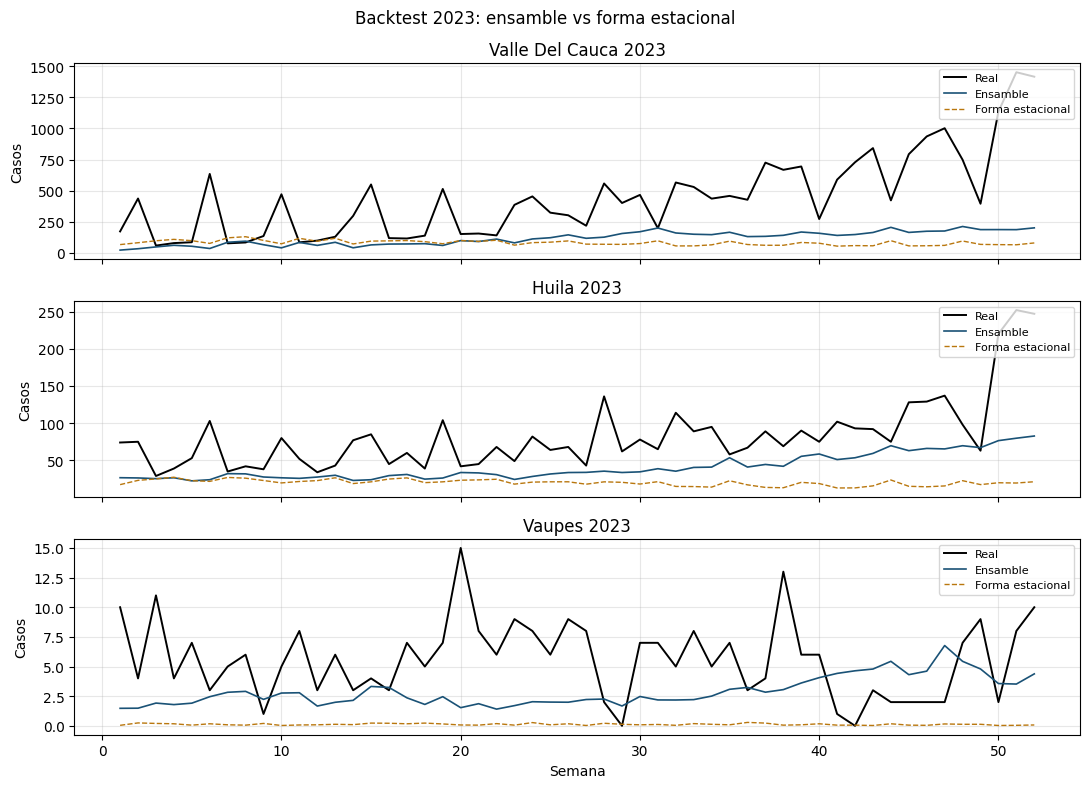

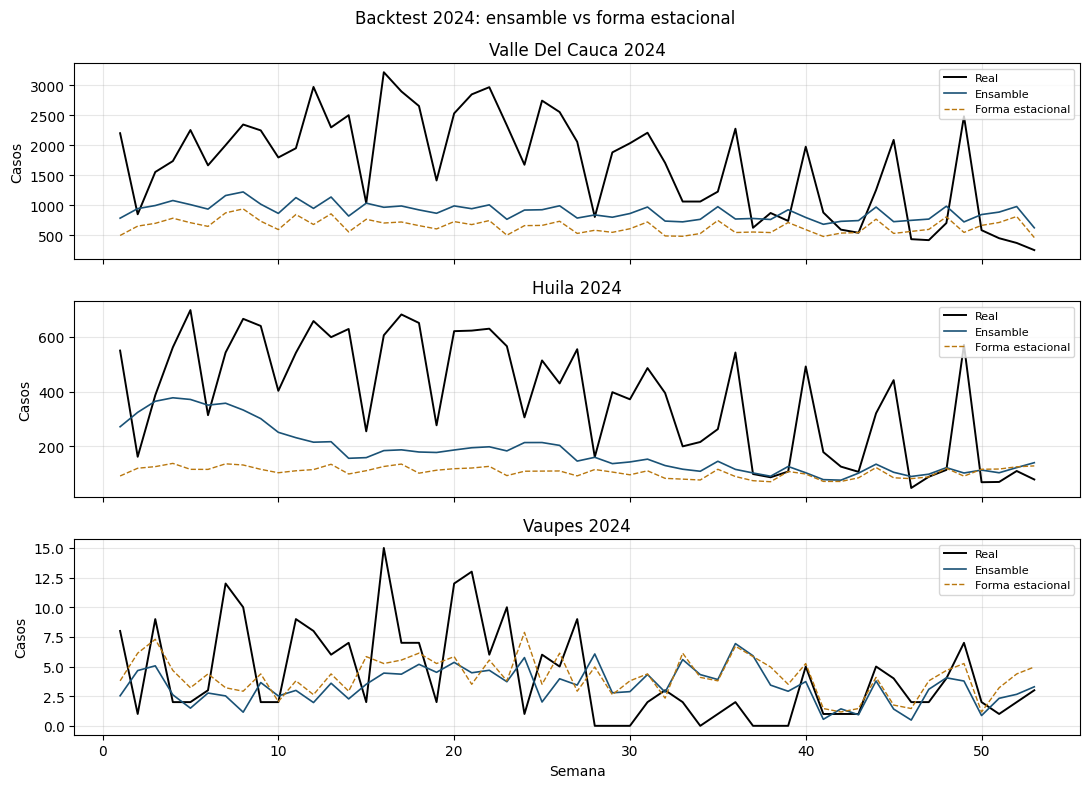

Pesos finales: {'GRU residual': 0.7, 'LSTM residual': 0.0, 'TCN residual': 0.3, 'forma': 0.0}
Listo para subir el archivo submission.csv


In [16]:
full = pd.concat([train, test], ignore_index=True)
features_full = build_features(full)
print("Filas con la prueba incluida:", features_full.shape, "anos", sorted(features_full.anio.unique().tolist())[-3:])

stage1_spec = SPECS[best_stage1_name]
stage1_pred = fit_test_predictions(
    stage1_spec["factory"],
    stage1_spec["columns"],
    stage1_spec["seq_len"],
    stage1_spec["residual"],
    stage1_spec["train_kwargs"],
    epochs=RUBRIC_EPOCHS,
    seed=42,
    frame=features_full,
)
to_submission(stage1_pred.rename(columns={"pred": "dengue"})[["ID", "dengue"]], repo_root() / "ensayos/juan/2026-10-27-rnn-etapa1/submission.csv")

test_parts = []
for seed in FINAL_SEEDS:
    print(f"\nSemilla final {seed}")
    seed_parts = []
    for model_name, model_spec in STAGE2_SPECS.items():
        print(" ", model_name)
        pred = fit_test_predictions(
            model_spec["factory"],
            COLS_STAGE2,
            model_spec["seq_len"],
            True,
            model_spec["train_kwargs"],
            epochs=FINAL_EPOCHS,
            seed=seed,
            frame=features_full,
        )
        seed_parts.append(pred[["ID", "pred"]].rename(columns={"pred": model_name}))
    merged_seed = seed_parts[0]
    for part in seed_parts[1:]:
        merged_seed = merged_seed.merge(part, on="ID", how="inner")
    test_parts.append(merged_seed)

ensemble_test = test_parts[0][["ID"]].copy()
for model_name in STAGE2_SPECS:
    ensemble_test[model_name] = sum(part[model_name] for part in test_parts) / len(test_parts)

shape_2025 = features_full.loc[features_full.anio == 2025, ["ID", "shape", "departamento", "semana"]]
final = ensemble_test.merge(shape_2025, on="ID", how="left")
final["dengue"] = 0.0
for weight, model_name in zip(best_weights, BLEND_NAMES):
    final["dengue"] = final["dengue"] + weight * final[model_name if model_name != "shape" else "shape"]
final["dengue"] = final["dengue"].clip(lower=0)

submission = to_submission(final[["ID", "dengue"]], repo_root() / "ensayos/juan/2026-10-27-ensamble-residual/submission.csv")
display(submission.head())

# El grafico compara el ensamble con lo ocurrido en 2023 y en 2024.
for holdout_year in (2023, 2024):
    bundle = bundles[holdout_year]
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for ax, dept in zip(axes, plot_departments):
        part = bundle[bundle.departamento == dept].sort_values("semana")
        ax.plot(part.semana, part.y, color="black", lw=1.4, label="Real")
        ax.plot(part.semana, part.ensamble, color="#1A5276", lw=1.2, label="Ensamble")
        ax.plot(part.semana, part["shape"], color="#B9770E", lw=1, ls="--", label="Forma estacional")
        ax.set_title(f"{dept} {holdout_year}")
        ax.set_ylabel("Casos")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("Semana")
    fig.suptitle(f"Validacion de {holdout_year}: ensamble y forma estacional")
    plt.tight_layout()
    plt.show()

print("Pesos finales:", dict(zip(["GRU residual", "LSTM residual", "TCN residual", "forma"], [round(float(w), 2) for w in best_weights])))
print("Ensamble residual guardado. No es el archivo vigente: copia el brote de 2024.")


## Discusion para quien tiene que usar el numero

Un MSE mas bajo no significa que el pronostico sirva igual en todos los departamentos. En Vaupes, fallar por 15 casos es un evento. En Valle del Cauca, fallar por 15 casos es ruido, y fallar por 400 casos en la semana del pico cambia la fumigacion y la ocupacion hospitalaria. Como el MSE nacional esta dominado por esos departamentos grandes, el ensamble se juzgo con la serie completa y los graficos se leyeron aparte en un departamento de carga alta, uno intermedio y uno bajo.

Que no hace este archivo: no distingue municipios, no modela el serotipo ni la movilidad entre departamentos, y no promete el valor de 2025 antes de ver el tablero. Copiar el final de 2024 castiga el tablero si 2025 vuelve a un ano normal. El archivo que se sube es el de la ultima seccion: no usa como nivel un ano departamental que haya sido un brote.

Para reproducir: ejecutar el cuaderno de arriba a abajo en esta carpeta (con `data/train.parquet`) o en un entorno de Kaggle con tarjeta grafica. Las celdas de entrenamiento ya quedan con salida. No hace falta volver a entrenar para leer la decision; si se vuelve a correr, la semilla 42 fija las comparaciones de la etapa 1.


## Backtest en la escala del tablero

El tablero publico usa solo el segundo semestre de 2025 (semanas 27 a 52). El puesto final lo decide el primer semestre, y ese numero no se publica. El primero del tablero publico esta en 1.897 y el grupo de cabeza queda entre 1.900 y 3.500.

El backtest de arriba decia 895 en 2022 y 56.119 en 2024. El 895 salia porque 2021 fue un ano normal y el modelo copiaba ese nivel. El archivo armado de esa forma copia el final de 2024: unos 105 casos por departamento y semana, y Valle del Cauca en el segundo semestre cerca de 700, contra una mediana historica cercana a 145. Contra un segundo semestre como el de 2018 o el de 2022, ese archivo queda entre 14.000 y 22.000. No falla la cuenta de 2024: falla el ano con el que se compara. El clima de 2025 se parece a 2014, 2016, 2017, 2020 y 2021, no a 2023 ni a 2024.

Aqui cada ano se predice solo con lo anterior, y el error se parte en semestre 1 y semestre 2. Un ano de un departamento no entra al perfil ni a los vecinos si su media supero 2,2 veces la mediana de los anos previos de ese departamento. Esos anos tampoco se usan como etiqueta, porque un brote como 2024 pesa tanto en el error cuadratico que el modelo aprende a repetirlo.


In [1]:
"""Pronostico que no arrastra el brote del ano anterior. Mide semestre 1 y 2 por separado."""
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_squared_error

def raiz_repo():
    aqui = Path.cwd().resolve()
    for carpeta in [aqui, *list(aqui.parents)[:4]]:
        if (carpeta / "data" / "train.parquet").exists():
            return carpeta
    return aqui


def carpeta_datos():
    candidatos = [
        Path("/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn"),
        Path("/kaggle/input/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn"),
        raiz_repo() / "data",
    ]
    for candidato in candidatos:
        if (candidato / "train.parquet").exists():
            return candidato
    raise FileNotFoundError("No se encontro train.parquet en las carpetas de datos esperadas.")


DATA_DIR = carpeta_datos()
train = pd.read_parquet(DATA_DIR / "train.parquet").sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
test = pd.read_parquet(DATA_DIR / "test.parquet").sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
CLIM = [
    "precip_chirps_mm", "temp_media_C", "temp_min_C", "temp_max_C",
    "humedad_suelo_capa1", "evapotranspiracion_mm",
]
LAGS = ["precip_chirps_mm", "temp_min_C", "humedad_suelo_capa1"]


def score(y, p, semana):
    y = np.asarray(y, float)
    p = np.clip(np.asarray(p, float), 0, None)
    sem = np.asarray(semana)
    return {
        "mse_h1": float(mean_squared_error(y[sem <= 26], p[sem <= 26])),
        "mse_h2": float(mean_squared_error(y[sem >= 27], p[sem >= 27])),
        "media_pred": float(p.mean()),
    }


def serie_clima(hist, filas):
    cols = ["id_departamento", "anio", "semana", *CLIM]
    panel = pd.concat([
        hist[cols].assign(_parte=0),
        filas[cols].assign(_parte=1),
    ], ignore_index=True).sort_values(["id_departamento", "anio", "semana"])
    g = panel.groupby("id_departamento", sort=False)
    for col in LAGS:
        panel[f"{col}_l4"] = g[col].shift(4)
        panel[f"{col}_l8"] = g[col].shift(8)
    panel["lluvia_4"] = g["precip_chirps_mm"].transform(lambda s: s.rolling(4, min_periods=1).mean())
    return panel[panel._parte == 1].drop(columns="_parte").reset_index(drop=True)


def anos_atipicos(hist, umbral=2.2):
    """Un ano es atipico en un departamento si su media supera 2.2 veces la mediana de los anos previos."""
    anual = hist.groupby(["id_departamento", "anio"]).casos_dengue.mean().reset_index()
    marcas = []
    for dept, grupo in anual.groupby("id_departamento"):
        grupo = grupo.sort_values("anio")
        vistos = []
        for fila in grupo.itertuples(index=False):
            if vistos and fila.casos_dengue > umbral * float(np.median(vistos)):
                marcas.append((dept, int(fila.anio)))
            vistos.append(float(fila.casos_dengue))
    return set(marcas)


def sin_atipicos(hist):
    marcas = anos_atipicos(hist)
    if not marcas:
        return hist
    clave = list(zip(hist.id_departamento.to_numpy(), hist.anio.to_numpy()))
    quedarse = [item not in marcas for item in clave]
    return hist.loc[quedarse]


def mapas_casos(hist):
    estable = sin_atipicos(hist)
    med = estable.groupby(["id_departamento", "semana"]).casos_dengue.median()
    mean = estable.groupby(["id_departamento", "semana"]).casos_dengue.mean()
    reciente = estable[estable.anio >= hist.anio.max() - 5]
    if reciente.empty:
        reciente = estable
    med6 = reciente.groupby(["id_departamento", "semana"]).casos_dengue.median()
    nivel = estable.groupby("id_departamento").casos_dengue.mean()
    prev = hist[hist.anio == hist.anio.max()]
    yoy = prev.set_index(["id_departamento", "semana"]).casos_dengue
    ancla = prev.sort_values("semana").groupby("id_departamento").tail(8).groupby("id_departamento").casos_dengue.mean()
    clima_med = hist.groupby(["id_departamento", "semana"])[CLIM].mean()
    ultimo = int(hist.anio.max())
    marcas = anos_atipicos(hist)
    pico = {dept for dept, anio in marcas if anio == ultimo}
    return med, mean, med6, nivel, yoy, ancla, clima_med, pico


def tomar(index, serie):
    return serie.reindex(index).to_numpy(float)


def matriz(hist, filas):
    base = serie_clima(hist, filas)
    med, mean, med6, nivel, yoy, ancla, clima_med, pico = mapas_casos(hist)
    idx = pd.MultiIndex.from_arrays([base.id_departamento, base.semana])
    mediana = np.nan_to_num(tomar(idx, med), nan=0.0)
    media = np.nan_to_num(tomar(idx, mean), nan=0.0)
    m6 = tomar(idx, med6)
    m6 = np.where(np.isnan(m6), mediana, m6)
    anterior = tomar(idx, yoy)
    anterior = np.where(np.isnan(anterior), mediana, anterior)
    es_pico = base.id_departamento.map(lambda dept: dept in pico).to_numpy()
    anterior = np.where(es_pico, mediana, anterior)
    # si el ano pasado no fue un brote, solo se arrastra el 20% del exceso
    encogido = np.clip(mediana + 0.2 * (anterior - mediana), 0, None)
    niv = tomar(pd.Index(base.id_departamento), nivel)
    niv = np.where(np.isnan(niv) | (niv <= 0), 1.0, niv)
    anc = tomar(pd.Index(base.id_departamento), ancla)
    anc = np.where(np.isnan(anc), niv, anc)
    anc = np.where(es_pico, niv, anc)
    frame = base.copy()
    frame["log_mediana"] = np.log1p(mediana)
    frame["log_media"] = np.log1p(media)
    frame["log_reciente"] = np.log1p(m6)
    frame["log_encogido"] = np.log1p(encogido)
    frame["ancla_sobre_nivel"] = anc / niv
    frame["es_pico"] = es_pico.astype(int)
    frame["seno"] = np.sin(2 * np.pi * frame.semana / 52)
    frame["coseno"] = np.cos(2 * np.pi * frame.semana / 52)
    for col in CLIM:
        normal = tomar(idx, clima_med[col])
        frame[f"anom_{col}"] = frame[col].to_numpy(float) - np.nan_to_num(normal, nan=0.0)
    frame["mediana"] = mediana
    frame["encogido"] = encogido
    frame["vecinos"] = vecinos(hist, frame)
    return frame


### Arbol y archivo de envio

El arbol es chico a proposito (15 hojas). Uno mas grande memoriza el brote y lo repite al ano siguiente. `mse_h2` es la columna comparable con el tablero publico. `mse_h1` es la que va a definir al ganador.


In [2]:
def vecinos(hist, filas, k=25):
    cols = CLIM + [f"{c}_l4" for c in LAGS]
    pred = np.full(len(filas), np.nan)
    marcas = anos_atipicos(hist)
    for dept, f in filas.groupby("id_departamento"):
        h = hist[hist.id_departamento == dept].sort_values(["anio", "semana"])
        if len(h) < k:
            continue
        lag = h.copy()
        g = lag.groupby("id_departamento", sort=False)
        for col in LAGS:
            lag[f"{col}_l4"] = g[col].shift(4)
        quedarse = np.asarray([(dept, int(anio)) not in marcas for anio in lag.anio.to_numpy()])
        lag = lag.iloc[quedarse]
        h = h.iloc[quedarse]
        if len(h) < k:
            continue
        H = lag[cols].to_numpy(float)
        F = f[cols].to_numpy(float)
        mu = np.nanmean(H, axis=0)
        sd = np.nanstd(H, axis=0)
        sd = np.where(sd < 1e-6, 1.0, sd)
        Hn = np.nan_to_num((H - mu) / sd)
        Fn = np.nan_to_num((F - mu) / sd)
        dist = ((Fn[:, None, :] - Hn[None, :, :]) ** 2).sum(axis=2)
        sem_f = f.semana.to_numpy()[:, None]
        sem_h = h.semana.to_numpy()[None, :]
        salto = np.abs(sem_f - sem_h)
        salto = np.minimum(salto, 53 - salto)
        dist = np.where(salto <= 4, dist, 1e6)
        kk = min(k, len(h))
        elegidos = np.argpartition(dist, kk - 1, axis=1)[:, :kk]
        casos = h.casos_dengue.to_numpy(float)
        pred[f.index.to_numpy()] = np.median(casos[elegidos], axis=1)
    mediana = filas["mediana"].to_numpy(float) if "mediana" in filas.columns else 0
    return np.where(np.isnan(pred), mediana, pred)


COLUMNAS = None


def columnas_modelo(frame):
    excluir = {"anio", "semana_inicio", "semana_fin", "departamento", "ID", "casos_dengue", "mediana", "encogido", "y"}
    return [c for c in frame.columns if c not in excluir]


CACHE = {}


def bloque_anio(fuente, year):
    if year not in CACHE:
        hist = fuente[fuente.anio < year]
        filas = fuente[(fuente.anio == year) & (fuente.semana <= 52)].copy()
        bloque = matriz(hist, filas)
        if "casos_dengue" in filas.columns:
            bloque["y"] = filas.casos_dengue.to_numpy(float)
        CACHE[year] = bloque
    return CACHE[year]


def entrenar(anio_objetivo, fuente):
    piezas = []
    for year in range(2011, anio_objetivo):
        bloque = bloque_anio(fuente, year)
        vistos = fuente[fuente.anio <= year]
        marcas = anos_atipicos(vistos)
        quedarse = [(int(dept), year) not in marcas for dept in bloque.id_departamento.to_numpy()]
        piezas.append(bloque.loc[np.asarray(quedarse)])
    train_x = pd.concat(piezas, ignore_index=True)
    cols = columnas_modelo(train_x)
    modelo = lgb.LGBMRegressor(
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=80,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        random_state=42,
        verbosity=-1,
    )
    modelo.fit(train_x[cols], train_x["y"], categorical_feature=["id_departamento"])
    return modelo, cols


def predecir_anio(anio, fuente, futuro=None):
    if futuro is None:
        frame = bloque_anio(fuente, anio)
    else:
        hist = fuente[fuente.anio < anio]
        frame = matriz(hist, futuro)
    modelo, cols = entrenar(anio, fuente)
    pred = modelo.predict(frame[cols])
    return frame, np.clip(pred, 0, None)


def tabla_backtest():
    filas = []
    for year in range(2014, 2025):
        frame, pred = predecir_anio(year, train)
        for nombre, valores in (("arbol", pred), ("mediana_sin_brote", frame.mediana.to_numpy())):
            filas.append({"anio": year, "modelo": nombre, **score(frame.y, valores, frame.semana)})
        print(year, "listo", flush=True)
    return pd.DataFrame(filas)


def guardar_envio():
    previo = raiz_repo() / "ensayos/juan/2026-10-27-nivel-sin-brote/submission.csv"
    previo.parent.mkdir(parents=True, exist_ok=True)
    media_anterior = None
    if previo.exists():
        media_anterior = float(pd.read_csv(previo).dengue.mean())
    ordenado = test.sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
    frame, pred = predecir_anio(2025, train, futuro=ordenado)
    if len(pred) != len(ordenado):
        raise RuntimeError("El pronostico no tiene una fila por cada semana de prueba.")
    if not np.array_equal(frame.id_departamento.to_numpy(), ordenado.id_departamento.to_numpy()):
        raise RuntimeError("El pronostico quedo desordenado respecto al archivo de prueba.")
    if not np.array_equal(frame.semana.to_numpy(), ordenado.semana.to_numpy()):
        raise RuntimeError("Las semanas del pronostico no coinciden con el archivo de prueba.")
    envio = ordenado[["ID"]].copy()
    envio["dengue"] = np.clip(pred, 0, None)
    muestra = pd.read_csv(DATA_DIR / "sample_submission.csv")
    final = muestra[["id"]].merge(envio.rename(columns={"ID": "id"}), on="id", how="left")
    if final.dengue.isna().any():
        raise RuntimeError("Faltan identificadores en el archivo de envio.")
    final.to_csv(previo, index=False)
    h1 = final.merge(ordenado.rename(columns={"ID": "id"})[["id", "semana"]], on="id")
    print("Archivo", previo.name, "filas", len(final),
          "media", round(float(final.dengue.mean()), 1),
          "semestre 1", round(float(h1.loc[h1.semana <= 26, "dengue"].mean()), 1),
          "semestre 2", round(float(h1.loc[h1.semana >= 27, "dengue"].mean()), 1))
    if media_anterior is not None:
        print("La media del archivo anterior era", round(media_anterior, 1))
    return final

tabla = tabla_backtest()
resumen = tabla.pivot(index="anio", columns="modelo", values=["mse_h1", "mse_h2"]).round(0)
print(resumen.to_string())
parecidos = [2014, 2016, 2017, 2018, 2020, 2021, 2022]
print("Media en anos cuyo clima se parece al de 2025")
print(tabla[tabla.anio.isin(parecidos)].groupby("modelo")[["mse_h1", "mse_h2"]].mean().round(0).to_string())
guardar_envio()


2014 listo


2015 listo


2016 listo


2017 listo


2018 listo


2019 listo


... (4 outputs left out)

2024 listo


          mse_h1                     mse_h2                  
modelo     arbol mediana_sin_brote    arbol mediana_sin_brote
anio                                                         
2014      4742.0            4604.0   5431.0            4915.0
2015      7217.0            7973.0   4812.0            5453.0
2016     22276.0           25106.0  12220.0           13119.0
2017       678.0             860.0    702.0             588.0
2018       430.0             473.0   1409.0            1372.0
2019      8501.0            8733.0  10172.0           10623.0
2020     17860.0           21262.0   4320.0            4758.0
2021       867.0            1398.0   4231.0            4637.0
2022      1215.0            1599.0   2672.0            3484.0
2023      5552.0            7122.0  17407.0           21853.0
2024    180556.0          208157.0  75048.0           89110.0
Media en anos cuyo clima se parece al de 2025
                   mse_h1  mse_h2
modelo                           
arbol             

Archivo submission.csv filas 1612 media 36.6 semestre 1 37.3 semestre 2 35.9
La media del archivo anterior era 104.9


,id,dengue
0,1_2025_1,0.000000
1,1_2025_2,5.760438
2,1_2025_3,5.065857
3,1_2025_4,2.386463
4,1_2025_5,2.788705
...,...,...
1607,32_2025_48,1.958723
1608,32_2025_49,1.990768
1609,32_2025_50,1.769770
1610,32_2025_51,4.622101


## Como leer esta tabla

`mse_h2` es lo comparable con el tablero publico. En un segundo semestre tranquilo el arbol queda en 702 (2017), 1.409 (2018) y 2.672 (2022). Esa es la escala de los envios que hoy van primeros (1.897 a 3.500), no la de 56.000. En 2016, 2019, 2023 y 2024 el error sigue alto: hubo un brote que el clima no alcanza a anticipar. El tablero publico, en 1.897, indica que el segundo semestre de 2025 no es un brote de ese tamano.

El archivo de `ensayos/juan/2026-10-27-nivel-sin-brote/` baja la media de 105 a 37 casos. En el segundo semestre, Valle del Cauca queda en 147 y Santander en 201, cerca de su nivel habitual, no en los cientos del brote de 2024. El semestre 1, que es el que define al ganador, usa la misma regla y no se puede ver hasta el cierre.
